# 객체탐지-3 · 모델비교 · YOLO실전

**한 줄 요약**

- 2단계(Faster R-CNN) · 1단계(SSD · YOLO) 탐지기의 구조 차이를 열어 보고
- 같은 사진 · 같은 기준으로 비교한 뒤 ultralytics YOLO로 학습 · 평가함

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. R-CNN → Fast → Faster R-CNN이 무엇을 바꿨는지와 RPN · 앵커의 역할을 말한다
2. SSD 디폴트 박스 수와 YOLO11 격자 예측 자리 수를 계산하고, 앵커 있음 · 없음을 구별한다
3. VOC XML · COCO JSON · YOLO txt를 서로 바꾸고 되돌려 검증하며, data.yaml을 쓴다
4. ultralytics predict · val · train의 입력 · 출력을 torchvision 출력과 대응시킨다
5. 같은 사진 · 같은 기준으로 세 모델을 비교해 프로젝트 모델과 크기(n · s · m)를 고른다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">프로젝트에 쓸 탐지 모델을 고를 때</td>
<td style="text-align: left;">2단계 vs 1단계 · 크기 n · s · m (1 · 3 · 4장)</td>
</tr>
<tr>
<td style="text-align: left;">받은 데이터가 COCO JSON · VOC XML일 때</td>
<td style="text-align: left;">YOLO txt 변환 · data.yaml (2장)</td>
</tr>
<tr>
<td style="text-align: left;">빠르게 학습 · 평가 결과를 내야 할 때</td>
<td style="text-align: left;">ultralytics predict · val · train (3 · 4장)</td>
</tr>
<tr>
<td style="text-align: left;">논문 · 블로그 점수를 내 데이터와 비교할 때</td>
<td style="text-align: left;">같은 사진 · 같은 기준 · 번호 맞추기 (4장)</td>
</tr>
</tbody>
</table>

## 학습 지도

<img src="images/od3_map.png" alt="객체탐지-3 학습 지도" width="763">

**예상 학습 시간** · 개념 2시간 + 실습 1시간 (GPU 기준 전체 실행 수 분 · YOLO 3 epoch 학습 포함)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">장</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">0</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">환경 변수 · 라이브러리 · seed · 경로 · 그림 도우미</td>
</tr>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">모델 계열 · 2단계 vs 1단계</td>
<td style="text-align: left;">2단계 · 1단계, 앵커 있음 · 없음은 구조가 어떻게 다른가?</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">데이터 형식</td>
<td style="text-align: left;">VOC XML · COCO JSON · YOLO txt는 어떻게 다르고 어떻게 바꾸는가?</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">ultralytics 사용법</td>
<td style="text-align: left;">predict · val · train은 무엇을 넣고 받으며, 크기는 어떻게 고르는가?</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">종합 실습</td>
<td style="text-align: left;">같은 사진에서 세 모델은 어떻게 다르고, YOLO를 학습하면 val mAP는?</td>
</tr>
<tr>
<td style="text-align: center;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 대응표 · 전체 코드</td>
</tr>
</tbody>
</table>

### 객체탐지 3권 · 핵심 기준

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">권</th>
<th style="text-align: left;">핵심 질문</th>
<th style="text-align: left;">핵심 숫자</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1 박스 · IoU · NMS · 채점</td>
<td style="text-align: left;">맞았는지 어떻게 채점하나?</td>
<td style="text-align: left;">IoU · AP50 · mAP</td>
</tr>
<tr>
<td style="text-align: left;">2 학습 · 평가 · 오류분석</td>
<td style="text-align: left;">내 클래스로 어떻게 학습 · 평가하나?</td>
<td style="text-align: left;">학습 손실 · 검증 mAP</td>
</tr>
<tr>
<td style="text-align: left;"><strong>3</strong> 모델 비교 · YOLO 실전 (이 권)</td>
<td style="text-align: left;">프로젝트에서는 무엇을 쓰나?</td>
<td style="text-align: left;">mAP · 속도 · 파라미터 수</td>
</tr>
</tbody>
</table>

- 권마다 묻는 질문 · 재료 전체 표는 부록 "이 노트북을 만든 방법"

---
## 0. 준비

환경 변수 · 라이브러리 · 경로 · 그림 도우미를 준비함. **셀은 위에서부터 차례로 실행**.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">설정</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">이유</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>YOLO_VERBOSE=False</code></td>
<td style="text-align: left;">ultralytics 진행 로그 끄기</td>
<td style="text-align: left;">import 전에 정해야 적용 → 0a 셀</td>
</tr>
<tr>
<td style="text-align: left;"><code>events.enabled = False</code></td>
<td style="text-align: left;">ultralytics 사용 통계 전송 끄기</td>
<td style="text-align: left;">이 실행에서만 끔 (설정 파일은 그대로)</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.manual_seed(0)</code> · <code>cudnn.deterministic</code> · <code>train(seed=0, deterministic=True)</code></td>
<td style="text-align: left;">난수 · 연산 고정</td>
<td style="text-align: left;">다시 실행해도 같은 값 (두 번 실행해 확인)</td>
</tr>
<tr>
<td style="text-align: left;"><code>device</code> · <code>DEV</code></td>
<td style="text-align: left;">GPU가 있으면 <code>cuda</code> · <code>0</code>, 없으면 <code>cpu</code></td>
<td style="text-align: left;">torchvision은 <code>device</code>, ultralytics는 <code>DEV</code>로 같은 장치</td>
</tr>
<tr>
<td style="text-align: left;"><code>WEIGHTS</code> · <code>COCO128</code> · <code>RUNS</code></td>
<td style="text-align: left;">노트북 옆 <code>weights/</code> · <code>datasets/coco128/</code> · <code>runs_객체탐지-3/</code></td>
<td style="text-align: left;">내려받은 파일 · 학습 결과 (GitHub에 안 올림)</td>
</tr>
</tbody>
</table>

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">데이터 · 모델</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">처음 나오는 곳</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>frcnn</code> · <code>ssd</code></td>
<td style="text-align: left;">torchvision COCO 사전학습 Faster R-CNN · SSD300</td>
<td style="text-align: left;">1-1 · 1-2</td>
</tr>
<tr>
<td style="text-align: left;"><code>yolo_n</code></td>
<td style="text-align: left;">ultralytics COCO 사전학습 YOLO11n (s · m은 3-2)</td>
<td style="text-align: left;">1-3</td>
</tr>
<tr>
<td style="text-align: left;">coco128</td>
<td style="text-align: left;">COCO 사진 128장 + YOLO txt 정답 (80 클래스)</td>
<td style="text-align: left;">2-2</td>
</tr>
<tr>
<td style="text-align: left;"><code>data_yaml</code></td>
<td style="text-align: left;">coco128용 data.yaml (직접 작성)</td>
<td style="text-align: left;">2-2</td>
</tr>
<tr>
<td style="text-align: left;">Oxford Pet XML</td>
<td style="text-align: left;">형식 변환 예시 (객체탐지-1 · 2와 같은 데이터)</td>
<td style="text-align: left;">2-1</td>
</tr>
</tbody>
</table>

In [1]:
# import 전에 정해야 적용되는 환경 변수
import os  # 환경 변수

os.environ["YOLO_VERBOSE"] = "False"         # ultralytics 진행 로그 끄기
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # numpy · torch OpenMP 충돌 방지

In [2]:
# 라이브러리 불러오기
import time                         # 속도 재기
import xml.etree.ElementTree as ET  # VOC XML 정답 (2-1)
from pathlib import Path            # 폴더 · 파일 경로

import kagglehub                                         # Oxford-IIIT Pet (2-1)
import matplotlib.pyplot as plt                          # 사진 · 그래프
import numpy as np                                       # 되돌리기 검증 (2-1)
import torch                                             # 텐서 · torchvision 모델
import torchvision.transforms.functional as TF           # PIL → 텐서
import ultralytics                                       # YOLO 라이브러리
from matplotlib import patches                           # 박스 그리기
from PIL import Image                                    # 사진 파일 열기
from torchmetrics.detection import MeanAveragePrecision  # 세 모델 같은 채점기
from ultralytics import YOLO                             # YOLO 모델 틀
from ultralytics.utils import events                     # 사용 통계 설정

events.events.enabled = False  # ultralytics 사용 통계 전송 끄기 (이 실행에서만)


# seed 고정 · 실행 장치
torch.manual_seed(0)                           # 난수 기준값 고정
torch.backends.cudnn.deterministic = True      # GPU 연산도 매번 같은 값
torch.backends.cudnn.benchmark = False         # 계산 방법이 실행마다 바뀌지 않게
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU 없으면 cpu
DEV = 0 if device.type == "cuda" else "cpu"    # ultralytics의 장치 표기
plt.rcParams["font.family"] = "Malgun Gothic"  # 그림 속 한글 (Windows)
plt.rcParams["axes.unicode_minus"] = False     # 음수 기호 깨짐 방지


# 경로: 노트북 옆 weights/ · datasets/ · runs (GitHub에 안 올림)
WEIGHTS = Path("weights")                                        # yolo11n · s · m.pt
COCO128 = Path("datasets") / "coco128"                           # 사진 128장 + YOLO txt 라벨
RUNS = Path("runs_객체탐지-3")                                   # ultralytics 학습 · 평가 결과
PET = Path(kagglehub.dataset_download(                           # 캐시에 있으면 경로만 받음
    "zippyz/cats-and-dogs-breeds-classification-oxford-dataset/versions/1"))
XMLS = PET / "annotations" / "annotations" / "xmls"              # VOC XML 정답
print("ultralytics", ultralytics.__version__, "| torch",         # 설치된 버전 · 장치 기록
      torch.__version__.split("+")[0], "| 실행 장치:", device.type)
print("weights:", sorted(p.name for p in WEIGHTS.glob("*.pt")),  # 준비된 파일 확인
      "| coco128 사진", len(list((COCO128 / "images").rglob("*.jpg"))), "장")

ultralytics 8.4.176 | torch 2.11.0 | 실행 장치: cuda
weights: ['yolo11m.pt', 'yolo11n.pt', 'yolo11s.pt'] | coco128 사진 128 장


In [3]:
# 그림 도우미: 정답 = 초록 · 예측 = 파랑
def show(img, gt=(), pred=(), labels=None, title="", ax=None):            # 사진 + 박스
    if ax is None:                                                        # 그릴 칸을 안 주면
        _, ax = plt.subplots(figsize=(5, 4))                              # 새 그림 하나
    ax.imshow(img)                                                        # 사진 깔기
    ax.axis("off")                                                        # 눈금 숨김
    for boxes, color in ((pred, "#0277bd"), (gt, "#2e7d32")):             # 예측 · 정답 순서
        for i, (x1, y1, x2, y2) in enumerate(boxes):                      # 박스마다 xyxy
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,    # (왼쪽 위, 너비, 높이)
                                           fill=False, ec=color, lw=2.5))
            if labels and color == "#0277bd":                             # 예측에만 이름표
                ax.text(x1 + 3, y1 + 3, labels[i], va="top", fontsize=8,  # 왼쪽 위 글자
                        color="white", bbox=dict(fc=color, ec="none", pad=1))
    ax.set_title(title, fontsize=10)                                      # 그림 제목
    return ax                                                             # 바깥에서 더 그릴 수 있게

---
## 1. 모델 계열 · 2단계 vs 1단계

> **이 장의 흐름**
>
> - 객체탐지-1 · 2에서 SSD와 Faster R-CNN을 써 봤다 → 두 모델과 YOLO가 후보 박스를 어떻게 만들고 몇 번 계산하는지 구조를 직접 열어 비교.
> - 속도 · 정확도 차이의 원인

**파이프라인 위치** · ④ 모델 — 후보 만들기 방식 · 앵커 있음 vs 없음

### 1-1. `A` 2단계 탐지기 · R-CNN에서 Faster R-CNN까지 · `fasterrcnn_resnet50_fpn()` · `rpn` <sub>Day01 D1-7 · PDF 19 ~ 66쪽</sub>

> 🎯 **R-CNN은 왜 느렸고, Fast R-CNN · Faster R-CNN은 무엇을 바꿔 빨라졌는가?**

💡 **쉽게 말하면**

- R-CNN은 **수천 장의 오려 낸 사진을 하나씩 감정사에게 보내는 것**.
- Fast는 사진 전체를 한 번만 감정하고 필요한 부분을 잘라 쓰고, Faster는 어디를 볼지(후보)까지 감정사가 직접 고름.

<img src="images/od3_families.png" alt="2단계는 후보 → 판정, 1단계는 칸마다 한 번에" width="763">

**실행 흐름**

1. 창문 수 계산 × CNN 1번 시간 (R-CNN 방식)
2. Faster R-CNN 열어 보기: 구성 4개 · RPN 앵커 크기 · 모양 · 후보 수 · 최종 분류 칸

**먼저 예측** · Faster R-CNN의 RPN은 다음 단계로 후보를 몇 개 넘길까? — 답은 코드 실행 결과 아래에

In [4]:
from torchvision.models import resnet18                                     # 시간만 잴 분류 CNN
from torchvision.models.detection import (FasterRCNN_ResNet50_FPN_Weights,  # 2단계 탐지기
                                          fasterrcnn_resnet50_fpn)

# R-CNN 방식: 후보(창문)마다 CNN을 따로 돌리면 몇 번?
W, H = 500, 375                                                    # 강의 예시 사진 크기
n_win = 0                                                          # 창문 수
for s in (64, 128, 256):                                           # 창문 크기 3가지
    for r in (0.5, 1, 2):                                          # 모양 3가지 (세로 ÷ 가로)
        w, h = int(s / r ** 0.5), int(s * r ** 0.5)                # 넓이는 같고 모양만 다름
        n_win += ((W - w) // 16 + 1) * ((H - h) // 16 + 1)         # 16픽셀씩
cnn = resnet18(weights=None).eval().to(device)                     # 시간만 재는 CNN
crop = torch.rand(1, 3, 224, 224, device=device)                   # 창문 하나 크기 입력
with torch.no_grad():                                              # 예측만
    cnn(crop)                                                      # 첫 실행 준비 시간 빼기
    t0 = time.perf_counter()                                       # 시작 시각
    for _ in range(20):                                            # 20번 평균
        cnn(crop)                                                  # CNN 한 번
    if device.type == "cuda":                                      # GPU는 비동기라
        torch.cuda.synchronize()                                   # 끝날 때까지 기다림
one = (time.perf_counter() - t0) / 20                              # CNN 한 번 시간
print(f"창문 {n_win}개 × CNN 1번 {one * 1000:.1f}ms ≈ 사진 한 장"  # 창문 수 × 한 번
      f" {one * n_win:.1f}초 (컴퓨터마다 다름)")


# Faster R-CNN: 후보도 네트워크(RPN)가 만들고, 특징은 한 번만 계산
frcnn = fasterrcnn_resnet50_fpn(                            # COCO 가중치 · 평가 모드
    weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1).eval().to(device)
for name, part in frcnn.named_children():                   # 큰 부품 이름
    print(f"{name:10s} → {type(part).__name__}")            # transform · backbone · rpn · roi_heads
gen = frcnn.rpn.anchor_generator                            # RPN의 앵커
print("RPN 앵커 크기:", [s[0] for s in gen.sizes], "| 모양(세로÷가로):",  # 크기 5 · 모양 3
      gen.aspect_ratios[0])
print("RPN이 넘기는 후보 수:", frcnn.rpn.post_nms_top_n(),  # 2단계로 넘기는 후보
      "| 최종 분류 칸 수:", frcnn.roi_heads.box_predictor.cls_score.out_features)

창문 2975개 × CNN 1번 2.4ms ≈ 사진 한 장 7.0초 (컴퓨터마다 다름)


transform  → GeneralizedRCNNTransform
backbone   → BackboneWithFPN
rpn        → RegionProposalNetwork
roi_heads  → RoIHeads
RPN 앵커 크기: [32, 64, 128, 256, 512] | 모양(세로÷가로): (0.5, 1.0, 2.0)
RPN이 넘기는 후보 수: 1000 | 최종 분류 칸 수: 91


**결과** · 예측 정답은 `1000`개 — 앵커(크기 5 × 모양 3)에서 출발해 NMS로 줄인 뒤 상위 1000개를 RoI Heads가 판정

- `창문 2975개 × CNN 1번` — 창문마다 CNN을 돌리면 사진 한 장에 수천 번 계산 (R-CNN의 병목, 시간은 컴퓨터마다 다름)
- `transform  → GeneralizedRCNNTransform` — 사진 크기 맞추기 · 정규화
- `backbone   → BackboneWithFPN` — ResNet50 + FPN: 사진 전체 특징을 한 번만 계산 (Fast R-CNN의 아이디어)
- `rpn        → RegionProposalNetwork` — 1단계: 앵커로 후보 박스 만들기 (Faster R-CNN의 아이디어)
- `roi_heads  → RoIHeads` — 2단계: 후보마다 잘라서 클래스 + 박스 보정
- `RPN 앵커 크기: [32, 64, 128, 256, 512] | 모양(세로÷가로): (0.5, 1.0, 2.0)` — 크기 5 × 모양 3 = 앵커 15종
- `RPN이 넘기는 후보 수: 1000 | 최종 분류 칸 수: 91` — 2단계로 넘어가는 후보 · COCO 91칸

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">R-CNN</td>
<td style="text-align: left;">후보(Selective Search) 약 2000개마다 CNN을 따로 · SVM 분류</td>
<td style="text-align: left;">역사적 출발점 (지금은 안 씀)</td>
</tr>
<tr>
<td style="text-align: left;">Fast R-CNN</td>
<td style="text-align: left;">사진 전체 특징을 한 번 계산 → 후보마다 RoI Pooling으로 잘라 씀</td>
<td style="text-align: left;">특징 공유의 아이디어</td>
</tr>
<tr>
<td style="text-align: left;">Faster R-CNN</td>
<td style="text-align: left;">후보도 네트워크(RPN · 앵커)가 만듦 → 끝까지 한 네트워크</td>
<td style="text-align: left;">정확도 우선 · 2단계 기본형</td>
</tr>
<tr>
<td style="text-align: left;">2단계 vs 1단계</td>
<td style="text-align: left;">후보 고르기 → 후보마다 판정 vs 한 번에 박스 + 클래스</td>
<td style="text-align: left;">정확 · 느림 vs 빠름 · 실시간</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 2단계는 후보마다 다시 판정하므로 정확하지만, 후보 수만큼 2단계 계산이 반복돼 1단계보다 느림 (4-1에서 실측)

> ✅ **한 줄 정리** · R-CNN은 후보마다 CNN을 돌려 느렸고, Fast는 특징을 공유하며, Faster는 후보 생성까지 RPN이 맡아 한 네트워크로 끝낸다.

**딥러닝 코드에서는**

- torchvision `fasterrcnn_resnet50_fpn` = RPN + RoI Heads, 객체탐지-2 3-2에서 `roi_heads.box_predictor`만 바꿔 학습

### 1-2. `A` 1단계 탐지기 SSD · 디폴트 박스 · `ssd300_vgg16()` · `anchor_generator` <sub>Day01 D1-8 · PDF 80 ~ 90쪽</sub>

> 🎯 **SSD는 후보 단계 없이 한 번에 어떻게 박스를 예측하는가?**

💡 **쉽게 말하면**

- SSD는 사진 위에 **크기가 다른 여러 장의 격자 투명지**를 겹쳐 놓고, 칸마다 미리 그려 둔 박스(디폴트 박스) 몇 개에 대해 "무엇인지 · 얼마나 옮길지"를 한꺼번에 적는 것.

**실행 흐름**

1. 300×300 가짜 입력
2. 특징 맵 6장의 크기 × 칸마다 박스 수
3. 디폴트 박스 전체
4. 첫 맵 분류 층 출력 채널

**먼저 예측** · SSD300의 디폴트 박스는 모두 몇 개일까? — 답은 코드 실행 결과 아래에

In [5]:
from torchvision.models.detection import SSD300_VGG16_Weights, ssd300_vgg16  # 1단계 탐지기

# SSD: 특징 맵 6장 × 칸마다 디폴트 박스 → 후보 단계 없이 한 번에
ssd = ssd300_vgg16(weights=SSD300_VGG16_Weights.COCO_V1).eval().to(device)  # COCO SSD
with torch.no_grad():                                                       # 모양만 확인
    feats = ssd.backbone(torch.rand(1, 3, 300, 300, device=device))         # 특징 맵 6장
per_cell = ssd.anchor_generator.num_anchors_per_location()                  # 맵마다 칸당 박스 수
total = 0                                                                   # 디폴트 박스 합
for f, a in zip(feats.values(), per_cell):                                  # 맵마다
    h, w = f.shape[-2:]                                                     # 맵 크기
    total += h * w * a                                                      # 칸 수 × 칸당 박스
    print(f"맵 {h:2d}×{w:<2d} · 칸마다 박스 {a}개 = {h * w * a:5d}")        # 맵별 박스 수
print("디폴트 박스 전체:", total)                                           # 8732
c0 = ssd.head.classification_head.module_list[0]                            # 첫 맵의 분류 층
print("첫 맵 분류 층 출력 채널:", c0.out_channels, "= 박스 4개 × 91칸")     # 364

맵 38×38 · 칸마다 박스 4개 =  5776
맵 19×19 · 칸마다 박스 6개 =  2166
맵 10×10 · 칸마다 박스 6개 =   600
맵  5×5  · 칸마다 박스 6개 =   150
맵  3×3  · 칸마다 박스 4개 =    36
맵  1×1  · 칸마다 박스 4개 =     4
디폴트 박스 전체: 8732
첫 맵 분류 층 출력 채널: 364 = 박스 4개 × 91칸


**결과** · 예측 정답은 `8732`개 — 38×38 맵이 5776개로 가장 많음 (작은 물체 담당)

- `맵 38×38 · 칸마다 박스 4개 =  5776` — 가장 촘촘한 맵 → 작은 물체
- `맵 19×19 · 칸마다 박스 6개 =  2166` — 중간 맵
- `맵  1×1  · 칸마다 박스 4개 =     4` — 가장 거친 맵 → 사진을 거의 채운 큰 물체
- `디폴트 박스 전체: 8732` — 5776 + 2166 + 600 + 150 + 36 + 4 = 8732 · 박스마다 91칸 점수 + 보정 4개
- `첫 맵 분류 층 출력 채널: 364 = 박스 4개 × 91칸` — 출력 채널 = 박스 수 × 클래스 수 (객체탐지-2 3-1에서 3칸으로 교체)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">SSD</td>
<td style="text-align: left;">특징 맵 6장 × 디폴트 박스(앵커) 8,732개마다 점수 + 보정</td>
<td style="text-align: left;">빠른 1단계 · 앵커 기반</td>
</tr>
<tr>
<td style="text-align: left;">Faster R-CNN의 앵커</td>
<td style="text-align: left;">RPN이 앵커로 후보를 만들고 2단계에서 다시 판정</td>
<td style="text-align: left;">후보 품질 → 정확도</td>
</tr>
<tr>
<td style="text-align: left;">디폴트 박스(앵커) 있음</td>
<td style="text-align: left;">미리 정한 크기 · 모양에서 출발해 보정</td>
<td style="text-align: left;">앵커 크기 · 비율 설계가 성능에 영향</td>
</tr>
<tr>
<td style="text-align: left;">SSD 작은 물체</td>
<td style="text-align: left;">앞쪽 큰 맵(38×38)이 담당하지만 특징이 얕음</td>
<td style="text-align: left;">작은 물체에 약한 편 → 증강 · 입력 크기</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - SSD의 작은 물체 담당(38×38)은 네트워크 앞쪽의 얕은 특징이라 작은 물체에 약한 편 → 4-1 작은 물체 AP에서 확인

> ✅ **한 줄 정리** · SSD는 크기가 다른 특징 맵 6장의 칸마다 디폴트 박스(앵커)를 두고, 박스마다 클래스 점수와 위치 보정을 한 번에 예측하는 1단계 탐지기다.

**딥러닝 코드에서는**

- `ssd.head.classification_head` · `regression_head` — 학습 때는 디폴트 박스와 정답을 IoU 0.5로 짝지어 손실 (객체탐지-2 4장의 `bbox_regression` · `classification`)

### 1-3. `A` YOLO11 · 앵커 없는 격자 · `YOLO()` · `model.stride` <sub>Day01 D1-10 · PDF 69 ~ 136쪽</sub>

> 🎯 **YOLO11은 SSD · Faster R-CNN과 무엇이 다르고, 모델 크기는 얼마나 다른가?**

💡 **쉽게 말하면**

- YOLO11은 **격자 칸마다 "내 중심에서 물체의 네 변까지 몇 칸"을 재는 줄자**.
- 미리 그려 둔 박스(앵커) 없이 칸 중심에서 바로 재므로 앵커 크기를 정할 필요가 없음.

**실행 흐름**

1. YOLO11n 불러오기
2. 격자 간격 · 640 입력의 격자 크기 · 예측 자리 수
3. 날것 출력 모양
4. 세 모델 파라미터 수 비교

**먼저 예측** · 640×640 입력에서 YOLO11n이 예측하는 자리는 모두 몇 개일까? — 답은 코드 실행 결과 아래에

In [6]:
# YOLO11n: 격자 3장 · 칸 중심에서 박스까지 거리를 예측 (앵커 없음)
yolo_n = YOLO(WEIGHTS / "yolo11n.pt")                                # 가장 작은 YOLO11
strides = [int(s) for s in yolo_n.model.stride]                      # 격자 간격 8 · 16 · 32
grids = [640 // s for s in strides]                                  # 640 입력의 격자 칸 수
print("격자 간격(픽셀):", strides, "→ 640×640 입력의 격자:", grids)  # 80 · 40 · 20
print("예측 자리 수:", " + ".join(f"{g}×{g}" for g in grids), "=",   # 칸마다 예측 하나
      sum(g * g for g in grids), "| 클래스 수:", len(yolo_n.names))


# 같은 입력 크기 640에서 출력 모양 확인 (예측 자리마다 박스 4 + 클래스 80)
net = yolo_n.model.to(device).eval()                      # ultralytics 안의 torch 모델
with torch.no_grad():                                     # 모양만 확인
    raw = net(torch.rand(1, 3, 640, 640, device=device))  # NMS 전 날것 출력
raw = raw[0] if isinstance(raw, (list, tuple)) else raw   # 버전마다 묶음 형태가 다름
print("YOLO 날것 출력 모양:", tuple(raw.shape), "= (사진, 4 + 80, 예측 자리)")  # (1, 84, 8400)


# 세 모델 · 같은 계산 단위로 비교: 파라미터 수
def n_params(m):                                   # 파라미터 개수
    return sum(p.numel() for p in m.parameters())  # 텐서마다 원소 수 합


for name, m in (("Faster R-CNN R50-FPN", frcnn), ("SSD300 VGG16", ssd),  # 세 모델
                ("YOLO11n", yolo_n.model)):
    print(f"{name:20s} 파라미터 {n_params(m) / 1e6:5.1f}M")              # 백만 단위

격자 간격(픽셀): [8, 16, 32] → 640×640 입력의 격자: [80, 40, 20]
예측 자리 수: 80×80 + 40×40 + 20×20 = 8400 | 클래스 수: 80
YOLO 날것 출력 모양: (1, 84, 8400) = (사진, 4 + 80, 예측 자리)
Faster R-CNN R50-FPN 파라미터  41.8M
SSD300 VGG16         파라미터  35.6M
YOLO11n              파라미터   2.6M


**결과** · 예측 정답은 `8400`개 = 80×80 + 40×40 + 20×20 — 자리마다 박스 4개 숫자 + 클래스 80칸

- `격자 간격(픽셀): [8, 16, 32] → 640×640 입력의 격자: [80, 40, 20]` — 8픽셀 격자 = 작은 물체, 32픽셀 격자 = 큰 물체 (FPN류 neck으로 섞음, PDF의 FPN 부분)
- `예측 자리 수: 80×80 + 40×40 + 20×20 = 8400 | 클래스 수: 80` — SSD 디폴트 박스(1-2)와 비슷한 수 · 앵커 없이 칸 중심 기준
- `YOLO 날것 출력 모양: (1, 84, 8400) = (사진, 4 + 80, 예측 자리)` — 박스 4 + 클래스 80 = 84, 배경 칸 없음 (클래스 점수가 모두 낮으면 배경)
- `Faster R-CNN R50-FPN 파라미터  41.8M` — 2단계 · 가장 큼
- `SSD300 VGG16         파라미터  35.6M` — 1단계 · VGG16 몸통이 대부분
- `YOLO11n              파라미터   2.6M` — 1단계 · 가장 작음 (Faster R-CNN의 약 16분의 1)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">앵커 있음 (SSD · Faster R-CNN · YOLOv2 ~ v5)</td>
<td style="text-align: left;">미리 정한 박스에서 얼마나 옮길지 예측</td>
<td style="text-align: left;">앵커 크기를 데이터에 맞춰야 함</td>
</tr>
<tr>
<td style="text-align: left;">앵커 없음 (YOLOv8 · YOLO11)</td>
<td style="text-align: left;">격자 칸 중심에서 네 변까지 거리를 예측</td>
<td style="text-align: left;">설계할 앵커가 없어 다루기 쉬움</td>
</tr>
<tr>
<td style="text-align: left;">YOLO 격자 3장 (8 · 16 · 32)</td>
<td style="text-align: left;">작은 · 중간 · 큰 물체를 나눠 담당 (FPN류 neck)</td>
<td style="text-align: left;">여러 크기 물체</td>
</tr>
<tr>
<td style="text-align: left;">파라미터 수</td>
<td style="text-align: left;">Faster R-CNN 41.8M · SSD 35.6M · YOLO11n 2.6M</td>
<td style="text-align: left;">작은 모델 = 빠름 · 기기 배포</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - YOLO의 클래스 번호는 0 ~ 79(80칸, 배경 없음)
> - torchvision COCO는 0 = 배경 · 1 ~ 90(91칸) → 두 모델을 비교할 때 번호를 맞춰야 함 (4-1)

> ✅ **한 줄 정리** · YOLO11은 앵커 없이 격자 칸 중심에서 박스를 바로 예측하는 1단계 탐지기이고, 같은 일을 훨씬 적은 파라미터로 한다.

**딥러닝 코드에서는**

- 강의 노트북의 yolov3u는 앵커 기반 · 103.8M 파라미터, 여기서는 사용자 승인 범위의 yolo11 n · s · m 사용 (사용법은 같음)

---
## 2. 데이터 형식

> **이 장의 흐름**
>
> - 1장의 모델들은 정답 파일 형식도 다르게 기대한다
> - → torchvision 예제(VOC XML) · 대회(COCO JSON) · ultralytics(YOLO txt)를 하나의 박스로 바꿔 보고
> - ultralytics의 폴더 · data.yaml 규칙을 확인

**파이프라인 위치** · ① 데이터 준비 — 형식 변환 · 폴더 구조 · data.yaml

### 2-1. `A` VOC XML · COCO JSON · YOLO txt 변환 · `cxcywh ÷ W · H` <sub>PDF 8쪽 · 보강</sub>

> 🎯 **같은 정답 박스를 세 가지 파일 형식으로 어떻게 적고, 어떻게 바꾸는가?**

💡 **쉽게 말하면**

- 같은 집 주소를 **도로명 · 지번 · 위도경도**로 적는 것.
- VOC는 두 모서리(픽셀), COCO는 모서리 + 크기(픽셀), YOLO는 가운데 + 크기를 사진 크기로 나눈 비율.

<img src="images/od3_formats.png" alt="같은 박스를 VOC · COCO · YOLO 세 형식으로" width="752">

**실행 흐름**

1. Oxford XML 한 개 읽기
2. COCO JSON 딕셔너리 (images · annotations · categories)
3. YOLO txt 한 줄
4. YOLO 줄을 다시 xyxy 픽셀로 되돌려 검증

**먼저 예측** · Abyssinian_173 머리 박스를 YOLO txt로 바꾸면 가운데 x는 얼마일까? — 답은 코드 실행 결과 아래에

In [7]:
# 같은 정답 하나를 세 형식으로: VOC XML → COCO JSON → YOLO txt
root = ET.parse(XMLS / "Abyssinian_173.xml").getroot()                      # VOC XML 한 개
W, H = int(root.findtext("size/width")), int(root.findtext("size/height"))  # 사진 크기
bb = root.find("object/bndbox")                                             # 첫 물체 박스
x1, y1, x2, y2 = [float(bb.findtext(k))                                     # 글자 → 실수
                  for k in ("xmin", "ymin", "xmax", "ymax")]
print("VOC XML  (xyxy 픽셀)       :", [x1, y1, x2, y2], f"| 사진 {W}×{H}")  # 원래 정답


# COCO JSON: 파일 하나에 images · annotations · categories, bbox = xywh 픽셀
coco = {"images": [{"id": 1, "file_name": "Abyssinian_173.jpg",              # 사진 목록
                    "width": W, "height": H}],
        "annotations": [{"id": 1, "image_id": 1, "category_id": 1,           # 물체 목록
                         "bbox": [x1, y1, x2 - x1, y2 - y1],
                         "area": (x2 - x1) * (y2 - y1), "iscrowd": 0}],
        "categories": [{"id": 1, "name": "cat"}, {"id": 2, "name": "dog"}]}  # 이름표
print("COCO JSON (xywh 픽셀)      :", coco["annotations"][0]["bbox"])        # 왼쪽 위 + 크기


# YOLO txt: 사진마다 txt 한 개, 한 줄 = "클래스 cx cy w h" (0~1, 클래스 0부터)
cx, cy = (x1 + x2) / 2 / W, (y1 + y2) / 2 / H                          # 가운데를 사진 크기로 나눔
line = f"0 {cx:.6f} {cy:.6f} {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}"  # 한 줄
print("YOLO txt (cxcywh 0~1)      :", line)                            # 0~1 비율


# 되돌리기 검증: YOLO 줄 → xyxy 픽셀이 원래와 같은가
c, a, b, w, h = line.split()                                            # 다섯 칸
a, b, w, h = float(a) * W, float(b) * H, float(w) * W, float(h) * H     # 픽셀로
back = [round(a - w / 2, 2), round(b - h / 2, 2), round(a + w / 2, 2),  # 가운데 ± 절반
        round(b + h / 2, 2)]
print("YOLO → xyxy 되돌리기       :", back, "| 원래와 같음:",           # 식 검증
      np.allclose(back, [x1, y1, x2, y2], atol=0.01))

VOC XML  (xyxy 픽셀)       : [241.0, 31.0, 310.0, 102.0] | 사진 400×267
COCO JSON (xywh 픽셀)      : [241.0, 31.0, 69.0, 71.0]
YOLO txt (cxcywh 0~1)      : 0 0.688750 0.249064 0.172500 0.265918
YOLO → xyxy 되돌리기       : [241.0, 31.0, 310.0, 102.0] | 원래와 같음: True


**결과** · 예측 정답은 `0.688750` = 가운데 275.5 ÷ 사진 폭 400

- `VOC XML  (xyxy 픽셀)       : [241.0, 31.0, 310.0, 102.0] | 사진 400×267` — 객체탐지-1 2-1과 같은 정답
- `COCO JSON (xywh 픽셀)      : [241.0, 31.0, 69.0, 71.0]` — 너비 310 - 241 = 69 · 높이 102 - 31 = 71
- `YOLO txt (cxcywh 0~1)      : 0 0.688750 0.249064 0.172500 0.265918` — 클래스 0(cat) · 가운데 · 크기를 사진 크기로 나눔
- `YOLO → xyxy 되돌리기       : [241.0, 31.0, 310.0, 102.0] | 원래와 같음: True` — 변환 식이 맞는지 되돌려서 확인

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">VOC XML</td>
<td style="text-align: left;">사진마다 XML 하나 · xyxy 픽셀 · 클래스 이름</td>
<td style="text-align: left;">Oxford Pet · PASCAL VOC · torchvision 예제</td>
</tr>
<tr>
<td style="text-align: left;">COCO JSON</td>
<td style="text-align: left;">데이터 전체가 JSON 하나 · xywh 픽셀 · category_id</td>
<td style="text-align: left;">COCO · 대회 데이터 · pycocotools 평가</td>
</tr>
<tr>
<td style="text-align: left;">YOLO txt</td>
<td style="text-align: left;">사진마다 txt 하나 · 클래스 번호(0부터) + cxcywh 0~1</td>
<td style="text-align: left;">ultralytics 학습</td>
</tr>
<tr>
<td style="text-align: left;">변환할 때 확인</td>
<td style="text-align: left;">박스 형식 · 픽셀 vs 0~1 · 클래스 번호 시작(0 · 1)</td>
<td style="text-align: left;">되돌려서 원래 숫자와 같은지 검증</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - YOLO txt의 클래스는 0부터(cat = 0), torchvision은 0이 배경이라 1부터(cat = 1) → 변환할 때 번호를 하나 밀어야 함

> ✅ **한 줄 정리** · VOC는 xyxy 픽셀, COCO는 xywh 픽셀, YOLO는 cxcywh를 사진 크기로 나눈 0~1이며, 변환한 뒤에는 되돌려서 원래 숫자와 같은지 확인한다.

**딥러닝 코드에서는**

- 프로젝트 데이터가 COCO JSON이면 `ultralytics.data.converter.convert_coco()`로 YOLO txt 폴더를 만들 수 있음 (직접 변환 식은 위와 같음)

### 2-2. `A` YOLO 폴더 구조와 data.yaml · `data.yaml` <sub>ultralytics 노트북</sub>

> 🎯 **ultralytics는 사진과 정답을 어떻게 짝짓고, 데이터 위치와 클래스 이름은 어디에 적는가?**

💡 **쉽게 말하면**

- 사진 폴더와 정답 폴더가 **같은 서랍 배치**를 하고 있어 파일 이름만으로 짝을 찾음.
- data.yaml은 그 서랍장의 **위치와 이름표 목록을 적은 안내문**.

**실행 흐름**

1. coco128 첫 사진
2. 같은 이름의 라벨 txt
3. 라벨 줄 수 · 앞 2줄
4. 라벨 없는 사진 수
5. data.yaml 직접 작성
6. 라벨 줄을 xyxy로 바꿔 그림

**먼저 예측** · 사진 `images/train2017/000000000009.jpg`의 라벨 파일 이름은? — 답은 코드 실행 결과 아래에

사진: images\train2017\000000000009.jpg → 라벨: labels\train2017\000000000009.txt
라벨 8 줄 · 앞 2줄: ['45 0.479492 0.688771 0.955609 0.5955', '45 0.736516 0.247188 0.498875 0.476417']
라벨 없는 사진: 2 장 (물체가 없으면 txt가 없어도 됨)
['train: images/train2017', 'val: images/train2017', 'names:', '  0: person'] ... 80 개 클래스


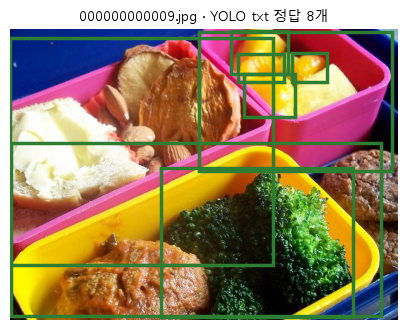

정답 클래스: ['bowl', 'bowl', 'broccoli', 'bowl', 'orange', 'orange', 'orange', 'orange']


In [8]:
# coco128 폴더: images/ 와 labels/ 가 같은 하위 경로 · 같은 파일 이름
img0 = sorted((COCO128 / "images" / "train2017").glob("*.jpg"))[0]               # 첫 사진
lab0 = COCO128 / "labels" / "train2017" / (img0.stem + ".txt")                   # 짝이 되는 라벨
print("사진:", img0.relative_to(COCO128), "→ 라벨:", lab0.relative_to(COCO128))  # 경로 규칙
lines = lab0.read_text().split("\n")                                             # 줄마다 물체 하나
lines = [ln for ln in lines if ln.strip()]                                       # 빈 줄 제거
print("라벨", len(lines), "줄 · 앞 2줄:", lines[:2])                             # 클래스 cx cy w h
no_label = [p for p in (COCO128 / "images" / "train2017").glob("*.jpg")          # txt 없는 사진
            if not (COCO128 / "labels" / "train2017"
                    / f"{p.stem}.txt").exists()]
print("라벨 없는 사진:", len(no_label), "장 (물체가 없으면 txt가 없어도 됨)")    # 배경 사진


# data.yaml: 데이터 위치 · 클래스 이름표 (ultralytics가 읽는 계약서)
names = yolo_n.names                                                   # 0 ~ 79 → COCO 이름
data_yaml = RUNS / "coco128.yaml"                                      # 노트북 옆 runs 폴더에 저장
data_yaml.parent.mkdir(exist_ok=True)                                  # 폴더가 없으면 만들기
data_yaml.write_text(                                                  # path · train · val · names
    f"path: {COCO128.resolve().as_posix()}\n"
    "train: images/train2017\nval: images/train2017\n"
    "names:\n" + "".join(f"  {i}: {n}\n" for i, n in names.items()),
    encoding="utf-8")
print(data_yaml.read_text(encoding="utf-8").splitlines()[1:5], "...",  # 앞부분만 확인
      len(names), "개 클래스")


# 그림: 라벨 줄을 xyxy 픽셀로 바꿔 그리기 (2-1 되돌리기 식)
img = Image.open(img0)                                                    # 사진
Wi, Hi = img.size                                                         # 폭 · 높이
boxes, labs = [], []                                                      # 박스 · 이름
for ln in lines:                                                          # 라벨 줄마다
    c, a, b, w, h = map(float, ln.split())                                # 다섯 칸 → 실수
    boxes.append([(a - w / 2) * Wi, (b - h / 2) * Hi, (a + w / 2) * Wi,   # xyxy 픽셀
                  (b + h / 2) * Hi])
    labs.append(names[int(c)])                                            # 번호 → 이름
show(img, gt=boxes, title=f"{img0.name} · YOLO txt 정답 {len(boxes)}개")  # 정답 그림
plt.show()                                                                # 그림 출력
print("정답 클래스:", labs)                                               # 이름 목록

**결과** · 예측 정답은 `labels/train2017/000000000009.txt` — images → labels, .jpg → .txt만 바꿈

- `라벨 8 줄 · 앞 2줄: ['45 0.479492 0.688771 0.955609 0.5955', '45 0.736516 0.247188 0.498875 0.476417']` — 한 줄 = 물체 하나 · 45번 = bowl
- `라벨 없는 사진: 2 장 (물체가 없으면 txt가 없어도 됨)` — 정답이 없는 2장 = 배경 사진
- `['train: images/train2017', 'val: images/train2017', 'names:', '  0: person'] ... 80 개 클래스` — 연습용 데이터라 train · val이 같은 사진 (실전에서는 나눔)
- `정답 클래스: ['bowl', 'bowl', 'broccoli', 'bowl', 'orange', 'orange', 'orange', 'orange']` — 라벨 번호 → data.yaml의 이름표

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>images/</code> · <code>labels/</code></td>
<td style="text-align: left;">같은 하위 경로 · 같은 파일 이름(확장자만 다름)</td>
<td style="text-align: left;">ultralytics가 짝을 찾는 규칙</td>
</tr>
<tr>
<td style="text-align: left;">data.yaml</td>
<td style="text-align: left;">path · train · val · names 계약서</td>
<td style="text-align: left;">학습 · 평가 모두 이 파일 하나로</td>
</tr>
<tr>
<td style="text-align: left;">라벨 txt 없음</td>
<td style="text-align: left;">물체가 없는 사진 (배경)</td>
<td style="text-align: left;">오류 아님</td>
</tr>
<tr>
<td style="text-align: left;">torchvision Dataset</td>
<td style="text-align: left;">직접 만든 <code>__getitem__</code>이 target dict를 돌려줌</td>
<td style="text-align: left;">객체탐지-2 · 직접 제어할 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - coco128은 train과 val이 같은 128장 → 4-2의 val mAP는 "본 사진을 다시 맞히는 점수"라 실력보다 높게 나옴, 실전은 객체탐지-2 1-1처럼 나눔

> ✅ **한 줄 정리** · ultralytics는 images/ · labels/의 같은 이름으로 짝짓고, data.yaml(path · train · val · names)을 학습 · 평가에 쓴다.

**딥러닝 코드에서는**

- 우리 데이터(예: Oxford 머리 박스)를 쓰려면 2-1 변환으로 labels/*.txt를 만들고 data.yaml의 names에 `0: cat` · `1: dog`

---
## 3. ultralytics 사용법

> **이 장의 흐름**
>
> - 2장에서 data.yaml을 만들었다 → ultralytics의 predict · val · train 세 모드가 무엇을 받고 무엇을 돌려주는지
> - torchvision과 무엇이 같고 다른지
> - 모델 크기는 어떻게 고르는지

**파이프라인 위치** · ④ 모델 · ⑥ 평가 — 예측 · 채점 · 크기 고르기

### 3-1. `A` predict · Results 읽기 · `model.predict()` · `Results.boxes` <sub>ultralytics 노트북</sub>

> 🎯 **ultralytics로 예측하면 무엇을 돌려받고, torchvision 탐지 모델 출력과 무엇이 같은가?**

💡 **쉽게 말하면**

- torchvision과 ultralytics는 **같은 내용을 다른 서식으로 적은 영수증**.
- boxes · scores · labels가 각각 boxes.xyxy · boxes.conf · boxes.cls로 이름만 바뀜.

**실행 흐름**

1. coco128 사진 한 장 predict(conf 0.25 · iou 0.7)
2. Results · boxes 개수 · 앞 2개
3. 같은 사진 Faster R-CNN 출력 이름 비교
4. conf · iou를 바꿔 박스 수

**먼저 예측** · conf를 0.25에서 0.5로 올리면 박스 수는 늘까 줄까? — 답은 코드 실행 결과 아래에

In [9]:
# predict: 사진 경로를 넣으면 Results 목록 (사진마다 하나)
r = yolo_n.predict(str(img0), conf=0.25, iou=0.7, device=DEV,      # 사진 한 장 → [0]
                   verbose=False)[0]
b = r.boxes                                                        # 박스 묶음
print("결과 종류:", type(r).__name__, "| 박스", len(b), "개")      # Results
print("xyxy 앞 2개:", b.xyxy[:2].round().tolist())                 # 픽셀 xyxy
print("conf 앞 2개:", [round(v, 2) for v in b.conf[:2].tolist()],  # 신뢰도 · 클래스
      "| cls 앞 2개:", [names[int(c)] for c in b.cls[:2]])


# torchvision과 같은 사진 · 같은 정보: 이름만 다름
img_t = TF.to_tensor(Image.open(img0).convert("RGB")).to(device)         # [3, H, W] 텐서
with torch.no_grad():                                                    # 예측만
    o = frcnn([img_t])[0]                                                # 사진 목록 → [0]
k = o["scores"] >= 0.25                                                  # 같은 신뢰도 기준
print(f"torchvision Faster R-CNN: boxes {tuple(o['boxes'][k].shape)} ·"  # 열쇠 이름 비교
      f" scores · labels | ultralytics: boxes.xyxy {tuple(b.xyxy.shape)}"
      " · boxes.conf · boxes.cls")


# 기준값: conf = 신뢰도 임곗값, iou = NMS 기준 (객체탐지-1 4장)
for conf, iou in ((0.25, 0.7), (0.5, 0.7), (0.25, 0.3)):               # 세 조합
    n = len(yolo_n.predict(str(img0), conf=conf, iou=iou, device=DEV,  # 남는 박스 수
                           verbose=False)[0].boxes)
    print(f"conf {conf} · iou {iou} → 박스 {n}개")                     # 기준마다 결과

결과 종류: Results | 박스 6 개
xyxy 앞 2개: [[309.0, 1.0, 630.0, 240.0], [256.0, 234.0, 566.0, 480.0]]
conf 앞 2개: [0.92, 0.85] | cls 앞 2개: ['bowl', 'broccoli']
torchvision Faster R-CNN: boxes (26, 4) · scores · labels | ultralytics: boxes.xyxy (6, 4) · boxes.conf · boxes.cls
conf 0.25 · iou 0.7 → 박스 6개
conf 0.5 · iou 0.7 → 박스 4개
conf 0.25 · iou 0.3 → 박스 6개


**결과** · 예측 정답은 줄어듦 — `6`개 → `4`개 (conf = 신뢰도 임곗값, 객체탐지-1 4-1)

- `결과 종류: Results | 박스 6 개` — 사진 한 장 = Results 하나
- `xyxy 앞 2개: [[309.0, 1.0, 630.0, 240.0], [256.0, 234.0, 566.0, 480.0]]` — 원본 사진 픽셀 기준 xyxy (torchvision과 같음)
- `conf 앞 2개: [0.92, 0.85] | cls 앞 2개: ['bowl', 'broccoli']` — 신뢰도 높은 순 · 클래스 번호 → `model.names`
- `conf 0.25 · iou 0.7 → 박스 6개` — 기본 설정
- `conf 0.5 · iou 0.7 → 박스 4개` — 신뢰도 기준을 올리면 줄어듦
- `conf 0.25 · iou 0.3 → 박스 6개` — NMS를 엄격하게 해도 이 사진은 겹친 중복이 없어 그대로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">torchvision 탐지 모델</td>
<td style="text-align: left;"><code>model([tensor])</code> → dict (boxes · scores · labels), 학습 루프 직접 작성</td>
<td style="text-align: left;">구조를 이해 · 수정 · 연구</td>
</tr>
<tr>
<td style="text-align: left;">ultralytics YOLO</td>
<td style="text-align: left;"><code>model.predict(경로)</code> → Results (boxes.xyxy · conf · cls), 학습 한 줄</td>
<td style="text-align: left;">빠른 프로젝트 · 배포</td>
</tr>
<tr>
<td style="text-align: left;"><code>conf</code></td>
<td style="text-align: left;">신뢰도 임곗값 (객체탐지-1 4-1)</td>
<td style="text-align: left;">결과 거르기</td>
</tr>
<tr>
<td style="text-align: left;"><code>iou</code></td>
<td style="text-align: left;">NMS 기준 (객체탐지-1 4-2)</td>
<td style="text-align: left;">겹친 중복 정리</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - torchvision 탐지 모델은 사진 텐서 목록을 받고, ultralytics는 경로 · 배열을 받아 크기 · 정규화를 알아서 함 → 입력 형식을 섞어 쓰지 않기

> ✅ **한 줄 정리** · predict는 사진마다 Results를 주고, boxes.xyxy · conf · cls는 torchvision의 boxes · scores · labels와 같은 정보다.

**딥러닝 코드에서는**

- 서비스 코드: `for r in model.predict(paths, conf=0.5): r.boxes.xyxy.cpu().numpy()` · 그림은 `r.plot()`

### 3-2. `A` YOLO 크기 n · s · m 고르기 · `get_flops()` · `model.val()` <sub>ultralytics 노트북 (yolov3u → yolo11)</sub>

> 🎯 **YOLO 모델 크기 n · s · m은 무엇이 다르고, 프로젝트에서는 어떻게 고르는가?**

💡 **쉽게 말하면**

- n · s · m은 **같은 설계의 S · M · L 사이즈 옷**.
- 클수록 계산이 많아 무겁지만 같은 사진을 더 잘 맞힘.

**실행 흐름**

1. yolo11n · s · m 차례로 불러오기
2. 파라미터 · 계산량(GFLOPs)
3. 같은 coco128 · 같은 기준으로 val mAP

**먼저 예측** · yolo11m은 n보다 계산량이 몇 배쯤 많고, mAP는 얼마나 오를까? — 답은 코드 실행 결과 아래에

In [10]:
from ultralytics.utils.torch_utils import get_flops  # 계산량 재기

# YOLO 크기 n · s · m: 파라미터 · 계산량 · 같은 데이터(coco128)의 val mAP
for tag in ("n", "s", "m"):                                                   # 세 크기
    m = YOLO(WEIGHTS / f"yolo11{tag}.pt")                                     # 사전학습 가중치
    v = m.val(data=str(data_yaml), imgsz=640, batch=16, conf=0.001, iou=0.7,  # 같은 조건 채점
              device=DEV, plots=False, verbose=False, workers=0,
              project=str(RUNS.resolve()), name=f"val_{tag}", exist_ok=True)
    print(f"yolo11{tag} | 파라미터 {n_params(m.model) / 1e6:4.1f}M |"         # 크기 · 계산량 · 점수
          f" 계산량 {get_flops(m.model, 640):4.1f} GFLOPs |"
          f" val mAP50 {v.box.map50:.4f} · mAP {v.box.map:.4f}")

yolo11n | 파라미터  2.6M | 계산량  6.7 GFLOPs | val mAP50 0.6707 · mAP 0.5028


yolo11s | 파라미터  9.5M | 계산량 21.8 GFLOPs | val mAP50 0.7520 · mAP 0.5743


yolo11m | 파라미터 20.1M | 계산량 68.6 GFLOPs | val mAP50 0.7975 · mAP 0.6220


**결과** · 예측 정답은 계산량 약 10배 (68.6 ÷ 6.7 = 10.2) · mAP `0.5028` → `0.6220`

- `yolo11n | 파라미터  2.6M | 계산량  6.7 GFLOPs | val mAP50 0.6707 · mAP 0.5028` — 가장 가벼움 · 3-3(0.6709)과의 넷째 자리 차이는 3-3 모델이 predict 때 Conv와 BN을 합친(fuse) 상태라 계산 순서가 조금 달라서
- `yolo11s | 파라미터  9.5M | 계산량 21.8 GFLOPs | val mAP50 0.7520 · mAP 0.5743` — 계산량 약 3배 · mAP +0.07
- `yolo11m | 파라미터 20.1M | 계산량 68.6 GFLOPs | val mAP50 0.7975 · mAP 0.6220` — 계산량 약 10배 · mAP +0.12

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">yolo11n</td>
<td style="text-align: left;">가장 작음 · 가장 빠름</td>
<td style="text-align: left;">실시간 · 저사양 · 첫 실험</td>
</tr>
<tr>
<td style="text-align: left;">yolo11s</td>
<td style="text-align: left;">중간</td>
<td style="text-align: left;">속도와 정확도 균형</td>
</tr>
<tr>
<td style="text-align: left;">yolo11m</td>
<td style="text-align: left;">가장 큼 · 가장 느림 · 보통 더 정확</td>
<td style="text-align: left;">정확도 우선 · GPU 여유</td>
</tr>
<tr>
<td style="text-align: left;">고르는 순서</td>
<td style="text-align: left;">n으로 파이프라인 확인 → 필요하면 s · m</td>
<td style="text-align: left;">프로젝트 기본 전략</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 실제 속도는 기기 · 배치 크기 · 다른 프로그램의 GPU 사용에 따라 달라짐
> - → 사진 한 장씩 GPU에 넣으면 호출 부담 때문에 크기 차이가 잘 안 보이므로 배포 환경에서 직접 잼

> ✅ **한 줄 정리** · n · s · m은 같은 구조의 크기 차이로, 클수록 계산량과 mAP가 함께 오르므로 n으로 파이프라인을 확인한 뒤 필요한 만큼 키운다.

**딥러닝 코드에서는**

- `YOLO("yolo11s.pt")`처럼 파일 이름만 바꾸면 predict · val · train 코드는 그대로

### 3-3. `A` predict · val · train 세 모드 · `predict · val · train` <sub>ultralytics 노트북</sub>

> 🎯 **ultralytics의 predict · val · train은 각각 무엇을 넣고 무엇을 돌려받는가?**

💡 **쉽게 말하면**

- 같은 학생에게 **문제만 주면 답안(predict)**, **정답지와 함께 주면 채점표(val)**, **교재를 주면 공부(train)**.
- 세 모드 모두 data.yaml 하나로 데이터를 찾음.

<img src="images/od3_modes.png" alt="predict · val · train: 넣는 것과 받는 것" width="763">

**실행 흐름**

1. 사전학습 yolo11n을 coco128로 val (conf 0.001 · iou 0.7)
2. mAP50 · mAP
3. 세 모드의 입력 · 출력 정리

**먼저 예측** · 학습 전 yolo11n의 coco128 val mAP50은 0.5를 넘을까? — 답은 코드 실행 결과 아래에

In [11]:
# val: data.yaml의 정답으로 채점 (사전학습 yolo11n · 학습 전)
val_n = yolo_n.val(data=str(data_yaml), imgsz=640, batch=16, conf=0.001,  # 4-2와 비교할 기준
                   iou=0.7, device=DEV,
                   plots=False, verbose=False, project=str(RUNS.resolve()),
                   name="val_n_before", exist_ok=True, workers=0)
print(f"val (학습 전) | mAP50 {val_n.box.map50:.4f} ·"                    # 학습 전 점수
      f" mAP@[.5:.95] {val_n.box.map:.4f}")


# 세 모드의 입력 · 출력 정리
modes = [("predict", "사진 경로 · 배열", "Results (boxes.xyxy · conf · cls)"),  # 예측
         ("val", "data.yaml (정답 포함)", "지표 (box.map50 · box.map)"),
         ("train", "data.yaml + epochs", "runs 폴더 (weights · 기록)")]
for mode, inp, out in modes:                                                    # 모드마다 한 줄
    print(f"{mode:7s} | 입력: {inp} → 출력: {out}")                             # 입력 → 출력

val (학습 전) | mAP50 0.6709 · mAP@[.5:.95] 0.5028
predict | 입력: 사진 경로 · 배열 → 출력: Results (boxes.xyxy · conf · cls)
val     | 입력: data.yaml (정답 포함) → 출력: 지표 (box.map50 · box.map)
train   | 입력: data.yaml + epochs → 출력: runs 폴더 (weights · 기록)


**결과** · 예측 정답은 넘음 — `0.6709` (COCO로 학습된 모델이라 COCO 사진은 이미 꽤 맞힘)

- `val (학습 전) | mAP50 0.6709 · mAP@[.5:.95] 0.5028` — 4-2 학습 전 기준선 · conf 0.001로 낮은 점수까지 모아 AP 계산
- `predict | 입력: 사진 경로 · 배열 → 출력: Results (boxes.xyxy · conf · cls)` — 정답 없이 예측만
- `val     | 입력: data.yaml (정답 포함) → 출력: 지표 (box.map50 · box.map)` — 채점 (객체탐지-1 6장의 COCO 방식)
- `train   | 입력: data.yaml + epochs → 출력: runs 폴더 (weights · 기록)` — 학습 · best.pt · last.pt · results.csv

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">predict</td>
<td style="text-align: left;">사진 → 예측 (정답 불필요)</td>
<td style="text-align: left;">결과 확인 · 서비스</td>
</tr>
<tr>
<td style="text-align: left;">val</td>
<td style="text-align: left;">data.yaml의 정답으로 채점 → mAP</td>
<td style="text-align: left;">모델 고르기 · 학습 전후 비교</td>
</tr>
<tr>
<td style="text-align: left;">train</td>
<td style="text-align: left;">data.yaml로 학습 → runs/에 best.pt · last.pt · results.csv</td>
<td style="text-align: left;">내 데이터에 맞추기</td>
</tr>
<tr>
<td style="text-align: left;">val의 conf 0.001</td>
<td style="text-align: left;">AP 계산용으로 낮은 점수까지 (객체탐지-1 6-2)</td>
<td style="text-align: left;">predict의 0.25와 다름</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - val의 conf 기본값 0.001은 AP 계산용, predict의 0.25는 보여 줄 결과용 → predict 결과로 mAP를 직접 계산하면 낮게 나옴 (객체탐지-1 6-2)

> ✅ **한 줄 정리** · predict는 사진으로 예측을, val은 data.yaml의 정답으로 mAP를, train은 data.yaml로 학습해 runs 폴더를 돌려준다.

**딥러닝 코드에서는**

- 객체탐지-2에서 직접 짠 `predict_all` · `evaluate` · `fit`을 ultralytics는 `predict` · `val` · `train` 한 줄씩으로 제공

---
## 4. 종합 실습 · 같은 사진으로 세 모델 비교 · YOLO 짧게 학습

> **이 장의 흐름**
>
> - 1 ~ 3장을 모두 사용
> - 1장에서 구조로만 본 세 모델을 **같은 사진 · 같은 정답 · 같은 기준**으로 실제로 돌림
> - 속도 · mAP · 작은 물체를 비교
> - ultralytics로 YOLO를 짧게 학습해 기록과 val mAP를 읽음

<img src="images/od3_compare.png" alt="세 모델 핵심 비교: mAP · 작은 물체 AP · 파라미터" width="950">

**파이프라인 위치** · ① data.yaml(2장) → ④ 세 모델(1장) → ⑥ 같은 기준 채점 → ⑤ 학습 → ⑥ val → ⑦ runs 폴더

> 🎯 **같은 사진 · 같은 기준에서 Faster R-CNN · SSD · YOLO는 속도와 정확도가 어떻게 다르고, YOLO를 짧게 학습하면 val mAP는 어떻게 바뀌는가?**

💡 **쉽게 말하면**

- 세 선수에게 **같은 문제지**(coco128 64장)를 같은 채점 기준으로 풀게 해 점수와 시간을 잼
- 그중 가장 빠른 선수(YOLO)를 조금 더 연습시켜 다시 채점함

### 4-1. 같은 사진 64장 · 같은 기준으로 세 모델 비교

**실행 흐름**

1. coco128 앞 64장 · YOLO txt 정답 → xyxy 픽셀 · COCO 번호(1 ~ 90)로 (2-1 · 2-2)
2. 같은 기준: 신뢰도 하한 0.001 · 사진당 최대 100개 · NMS는 각 모델 기본 (3-1)
3. 세 모델 예측 · 사진 한 장 평균 시간 (1장)
4. torchmetrics로 mAP50 · mAP · 작은 물체 · 큰 물체 AP (객체탐지-1 6장)

**먼저 예측** · 파라미터가 가장 적은 YOLO11n은 mAP에서 Faster R-CNN보다 많이 낮을까? — 답은 코드 실행 결과 아래에

In [12]:
from ultralytics.data.converter import coco80_to_coco91_class  # 번호 맞추기 표

# 같은 사진 64장 · 같은 정답 (YOLO 0 ~ 79 → COCO 번호 1 ~ 90으로 맞춤)
to91 = coco80_to_coco91_class()                                         # 80칸 번호 → 91칸 번호
photos = sorted((COCO128 / "images" / "train2017").glob("*.jpg"))[:64]  # 앞 64장


def coco_target(p):  # YOLO txt → torchmetrics 정답 dict
    W, H = Image.open(p).size                                         # 사진 크기
    lab = COCO128 / "labels" / "train2017" / (p.stem + ".txt")        # 짝 라벨
    text = lab.read_text() if lab.exists() else ""                    # 라벨 없음 = 빈 정답
    rows = [list(map(float, ln.split())) for ln in text.splitlines()  # 줄마다 다섯 숫자
            if ln.strip()]
    boxes = [[(a - w / 2) * W, (b - h / 2) * H, (a + w / 2) * W,      # cxcywh 0~1 → xyxy 픽셀
              (b + h / 2) * H] for _, a, b, w, h in rows]
    return {"boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),  # 빈 정답도 [0, 4]
            "labels": torch.tensor([to91[int(c)] for c, *_ in rows],
                                   dtype=torch.int64)}


# 같은 기준: 신뢰도 하한 0.001 · 사진당 최대 100개 · NMS는 각 모델 기본
frcnn.roi_heads.score_thresh = 0.001                                # Faster R-CNN 신뢰도 하한
frcnn.roi_heads.detections_per_img = 100                            # 사진당 최대 100개
ssd.score_thresh, ssd.detections_per_img = 0.001, 100               # SSD도 같게
tv_models = {"Faster R-CNN": frcnn, "SSD300": ssd}                  # torchvision 두 모델
targets = [coco_target(p) for p in photos]                          # 정답 64개
preds, sec = {"Faster R-CNN": [], "SSD300": [], "YOLO11n": []}, {}  # 예측 · 시간
for name in preds:                                                  # 모델마다
    if device.type == "cuda":                                       # GPU 대기열 비우고
        torch.cuda.synchronize()                                    # 시간 재기 시작
    t0 = time.perf_counter()                                        # 시작 시각
    for p in photos:                                                # 사진마다
        if name == "YOLO11n":                                       # ultralytics
            b = yolo_n.predict(str(p), conf=0.001, max_det=100,     # 같은 기준
                               verbose=False)[0].boxes
            out = {"boxes": b.xyxy, "scores": b.conf,               # torchvision 형식으로
                   "labels": torch.tensor([to91[int(c)] for c in b.cls])}
        else:                                                       # torchvision
            with torch.no_grad():                                   # 예측만
                out = tv_models[name]([TF.to_tensor(                # 사진 목록 → [0]
                    Image.open(p).convert("RGB")).to(device)])[0]
        preds[name].append({k: v.cpu() for k, v in out.items()})    # CPU로 모으기
    if device.type == "cuda":                                       # 남은 GPU 작업까지
        torch.cuda.synchronize()                                    # 기다림
    sec[name] = (time.perf_counter() - t0) / len(photos)            # 사진 한 장 시간

Faster R-CNN | mAP50 0.7580 · mAP 0.5063 · 작은 물체 0.3221 · 큰 물체 0.6029


SSD300       | mAP50 0.5428 · mAP 0.3208 · 작은 물체 0.0728 · 큰 물체 0.5143


YOLO11n      | mAP50 0.6808 · mAP 0.4920 · 작은 물체 0.2241 · 큰 물체 0.6604
Faster R-CNN | 사진 한 장 76ms (컴퓨터마다 다름)
SSD300       | 사진 한 장 55ms (컴퓨터마다 다름)
YOLO11n      | 사진 한 장 27ms (컴퓨터마다 다름)
빠른 모델: YOLO11n | 정답 박스 542 개


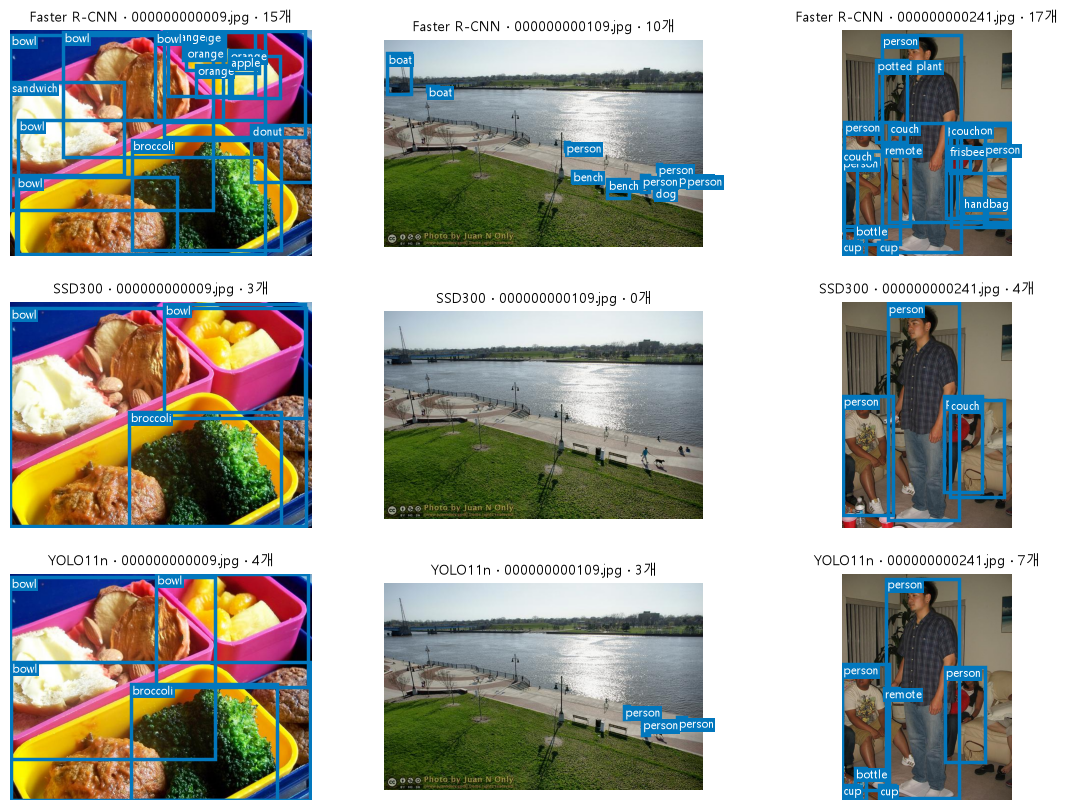

In [13]:
# 채점: torchmetrics (객체탐지-1 6장) · 크기별 AP 포함
for name, pr in preds.items():                                            # 모델마다 같은 채점기
    m = MeanAveragePrecision()                                            # COCO 방식
    m.warn_on_many_detections = False                                     # 경고 끔
    m.update(pr, targets)                                                 # 예측 · 정답
    r = m.compute()                                                       # 계산
    print(f"{name:12s} | mAP50 {r['map_50']:.4f} · mAP {r['map']:.4f} ·"  # 크기별 AP까지
          f" 작은 물체 {r['map_small']:.4f} · 큰 물체 {r['map_large']:.4f}")
for name, s in sec.items():                                               # 속도
    print(f"{name:12s} | 사진 한 장 {s * 1000:.0f}ms (컴퓨터마다 다름)")  # ms
print("빠른 모델:", min(sec, key=sec.get), "| 정답 박스",                 # 가장 빠른 모델 · 정답 수
      sum(len(t["boxes"]) for t in targets), "개")


# 그림: 같은 사진 · 신뢰도 0.5 이상
COCO_NAMES = FasterRCNN_ResNet50_FPN_Weights.COCO_V1.meta["categories"]  # 91칸 이름
fig, axes = plt.subplots(3, 3, figsize=(14, 10))                         # 줄 = 모델, 칸 = 사진
for col, i in enumerate((0, 20, 40)):                                    # 사진 3장
    img = Image.open(photos[i])                                          # 사진
    for row, name in enumerate(preds):                                   # 모델마다
        pr = preds[name][i]                                              # 이 사진 예측
        k = pr["scores"] >= 0.5                                          # 0.5 이상만
        show(img, pred=pr["boxes"][k].tolist(),                          # 예측 박스 · 이름
             labels=[COCO_NAMES[c] for c in pr["labels"][k].tolist()],
             title=f"{name} · {photos[i].name} · {int(k.sum())}개",
             ax=axes[row, col])
plt.show()                                                               # 그림 출력

**결과** · 예측 정답은 많이 낮지 않음 — mAP `0.4920` vs `0.5063`, 파라미터는 약 16분의 1인데 가장 빠르고 큰 물체는 오히려 가장 높음

- `Faster R-CNN | mAP50 0.7580 · mAP 0.5063 · 작은 물체 0.3221 · 큰 물체 0.6029` — 2단계 · mAP와 작은 물체가 가장 높음 (후보마다 다시 판정 · FPN 고해상도 특징)
- `SSD300       | mAP50 0.5428 · mAP 0.3208 · 작은 물체 0.0728 · 큰 물체 0.5143` — 300×300으로 줄여 보는 1단계 · 작은 물체가 크게 약함 (1-2 주의)
- `YOLO11n      | mAP50 0.6808 · mAP 0.4920 · 작은 물체 0.2241 · 큰 물체 0.6604` — 가장 작은 모델인데 mAP는 Faster R-CNN에 가깝고 큰 물체는 가장 높음
- `빠른 모델: YOLO11n | 정답 박스 542 개` — 실행할 때마다 YOLO가 가장 빠름 (Faster R-CNN보다 약 3 ~ 11배 · GPU를 함께 쓰는 프로그램에 따라 배수가 크게 달라짐)

**해석**

- 정확도(특히 작은 물체)를 가장 중시하면 Faster R-CNN
- 속도 · 가벼움 · 배포를 중시하면 YOLO
- SSD는 둘 사이의 옛 절충안이라 지금은 YOLO가 대신하는 경우가 많음
- coco128은 COCO **train** 사진이라 세 모델 모두 학습 때 봤을 수 있음 → 절대 점수보다 **같은 조건에서의 순서**로 읽음
- 도구 차이: torchvision 두 모델은 직접 조립 · 학습 루프 작성(구조를 바꿀 때), ultralytics는 한 줄 API · 자동 기록(빨리 결과를 낼 때)

**차이 · 언제 쓰나** (핵심 기준만)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">모델</th>
<th style="text-align: left;">핵심 기준 (같은 64장)</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Faster R-CNN (2단계 · 앵커)</td>
<td style="text-align: left;">mAP 0.5063 최고 · 작은 물체 0.3221 최고 · 가장 느림 · 41.8M</td>
<td style="text-align: left;">정확도 · 작은 물체 우선 · 오프라인 분석</td>
</tr>
<tr>
<td style="text-align: left;">SSD300 (1단계 · 앵커)</td>
<td style="text-align: left;">mAP 0.3208 · 작은 물체 0.0728 · 35.6M</td>
<td style="text-align: left;">구조 이해용 · 가벼운 옛 모델</td>
</tr>
<tr>
<td style="text-align: left;">YOLO11n (1단계 · 앵커 없음)</td>
<td style="text-align: left;">mAP 0.4920 · 큰 물체 0.6604 최고 · 가장 빠름 · 2.6M</td>
<td style="text-align: left;">실시간 · 배포 · 프로젝트 첫 선택</td>
</tr>
</tbody>
</table>

### 4-2. coco128로 YOLO 짧게 학습 → val mAP 읽기

**실행 흐름**

1. 사전학습 yolo11n → `train(data=data.yaml, epochs=3, seed=0, deterministic=True)` (3-3)
2. `runs_객체탐지-3/train_n/results.csv`에서 epoch마다 손실 · val mAP (객체탐지-2 5-1)
3. `best.pt`로 다시 val → 학습 전(3-3)과 비교 (3-3)

**먼저 예측** · 3 epoch만 학습해도 val mAP50이 오를까? — 답은 코드 실행 결과 아래에

In [14]:
# coco128로 yolo11n을 짧게 학습 (3 epoch · seed 0 · 결정적 연산)
model_tr = YOLO(WEIGHTS / "yolo11n.pt")                                     # 사전학습에서 출발
t0 = time.perf_counter()                                                    # 시작 시각
model_tr.train(data=str(data_yaml), epochs=3, imgsz=640, batch=16, seed=0,  # 재현 설정
               deterministic=True, amp=False, workers=0, plots=False,
               device=DEV, verbose=False,
               project=str(RUNS.resolve()), name="train_n", exist_ok=True)
print(f"학습 시간 약 {(time.perf_counter() - t0) / 60:.1f}분 (컴퓨터마다 다름)")  # 걸린 시간


# 학습 기록(results.csv)에서 epoch마다 손실 · val mAP 읽기
rows = (RUNS / "train_n" / "results.csv").read_text().strip().split("\n")  # 줄 목록
head = [h.strip() for h in rows[0].split(",")]                             # 열 이름
for row in rows[1:]:                                                       # epoch마다
    v = dict(zip(head, row.split(",")))                                    # 열 이름 → 값
    ep, loss = int(float(v["epoch"])), float(v["train/box_loss"])          # epoch · 박스 손실
    print(f"epoch {ep} | box_loss {loss:.3f}"                              # 손실 · val 점수
          f" | val mAP50 {float(v['metrics/mAP50(B)']):.4f}"
          f" · mAP {float(v['metrics/mAP50-95(B)']):.4f}")


# best.pt로 다시 val → 학습 전(3-3)과 비교
best = YOLO(RUNS / "train_n" / "weights" / "best.pt")                        # val 최고 가중치
val_after = best.val(data=str(data_yaml), imgsz=640, batch=16, conf=0.001,   # 3-3과 같은 조건
                     iou=0.7, plots=False, verbose=False, workers=0,
                     device=DEV,
                     project=str(RUNS.resolve()), name="val_n_after",
                     exist_ok=True)
print(f"학습 전 mAP50 {val_n.box.map50:.4f} → 학습 후 {val_after.box.map50:.4f}"  # 전 → 후
      f" | mAP {val_n.box.map:.4f} → {val_after.box.map:.4f}")
saved = sorted(p.name for p in (RUNS / "train_n" / "weights").glob("*.pt"))  # 저장 파일
print("저장된 파일:", saved)                                                 # best.pt · last.pt

학습 시간 약 0.2분 (컴퓨터마다 다름)
epoch 1 | box_loss 1.173 | val mAP50 0.6852 · mAP 0.5118
epoch 2 | box_loss 1.140 | val mAP50 0.7015 · mAP 0.5221
epoch 3 | box_loss 1.107 | val mAP50 0.7097 · mAP 0.5285


학습 전 mAP50 0.6709 → 학습 후 0.7066 | mAP 0.5028 → 0.5265
저장된 파일: ['best.pt', 'last.pt']


**결과** · 예측 정답은 오름 — `0.6709` → `0.7066`, 다만 coco128은 train과 val이 같은 사진이라 "본 사진을 다시 맞히는 점수"

- `epoch 1 | box_loss 1.173 | val mAP50 0.6852 · mAP 0.5118` — 첫 epoch부터 학습 전(0.6709)보다 오름
- `epoch 3 | box_loss 1.107 | val mAP50 0.7097 · mAP 0.5285` — 손실은 내려가고 val mAP는 오름 · 두 번 실행해 epoch별 값이 같음
- `학습 전 mAP50 0.6709 → 학습 후 0.7066 | mAP 0.5028 → 0.5265` — best.pt를 따로 다시 평가한 값
  - 학습 중 기록(0.7097)과 다른 것은 학습 루프 안 평가와 따로 한 평가의 계산 과정 차이
- `저장된 파일: ['best.pt', 'last.pt']` — 객체탐지-2 5-2와 같은 규칙: best = 평가 · 배포, last = 이어 학습(`resume=True`)

**결과를 적는 한 문장**

- 조건: coco128(train = val 128장) · yolo11n(COCO 사전학습) · 3 epoch · imgsz 640 · batch 16 · seed 0
- 결과: best.pt val mAP50 0.7066 · mAP@[.5:.95] 0.5265 (ultralytics val · conf 0.001 · iou 0.7)
- 비교: 학습 전 0.6709 · 0.5028

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">객체탐지-2의 직접 학습 루프</td>
<td style="text-align: left;">Dataset · collate · 헤드 교체 · 루프 · 저장을 모두 작성</td>
<td style="text-align: left;">구조를 바꾸거나 원리를 확인할 때</td>
</tr>
<tr>
<td style="text-align: left;">ultralytics <code>train</code></td>
<td style="text-align: left;">data.yaml + 한 줄 → runs 폴더에 기록 · best · last 자동</td>
<td style="text-align: left;">프로젝트에서 빠르게 학습할 때 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">학습 중 기록 (results.csv)</td>
<td style="text-align: left;">epoch마다 val mAP · 손실</td>
<td style="text-align: left;">학습 곡선 · epoch 고르기</td>
</tr>
<tr>
<td style="text-align: left;">학습 뒤 <code>best.pt</code> val</td>
<td style="text-align: left;">고른 모델을 같은 기준으로 다시 채점</td>
<td style="text-align: left;">보고 · 모델 비교</td>
</tr>
<tr>
<td style="text-align: left;">train = val (coco128)</td>
<td style="text-align: left;">본 사진 점수 → 실력보다 높음</td>
<td style="text-align: left;">연습 · 파이프라인 확인용만</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - train과 val이 같은 데이터면 점수가 높아도 새 사진 성능을 말할 수 없음
> - 프로젝트에서는 객체탐지-2 1-1처럼 train · val · test를 나눈 data.yaml을 만듦

> ✅ **한 줄 정리** · 같은 기준으로 비교하면 Faster R-CNN은 정확도 · 작은 물체, YOLO는 속도 · 가벼움에서 앞선다.

**딥러닝 코드에서는**

- 프로젝트 첫 실험은 `YOLO("yolo11n.pt").train(data="my.yaml", epochs=..)`
- `results.csv` · `best.pt`로 결과를 읽음
- 작은 물체가 중요하면 크기(s · m) · 입력 크기(imgsz)를 키우거나 Faster R-CNN과 비교
- ultralytics는 data.yaml 하나로 학습 · 평가 기록을 runs 폴더에 남김

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. 2단계 탐지기</td>
<td style="text-align: left;">창문 2975개 × CNN → RPN이 후보 1000개를 넘기는 Faster R-CNN</td>
<td style="text-align: left;">1-1</td>
</tr>
<tr>
<td style="text-align: left;">2. 디폴트 박스 · 격자</td>
<td style="text-align: left;">SSD 8732개, YOLO11n 80×80 + 40×40 + 20×20 = 8400 (앵커 없음)</td>
<td style="text-align: left;">1-2 · 1-3</td>
</tr>
<tr>
<td style="text-align: left;">3. 형식 변환 · data.yaml</td>
<td style="text-align: left;"><code>[241, 31, 310, 102]</code> → <code>0 0.688750 …</code> → 되돌려 같음</td>
<td style="text-align: left;">2-1 · 2-2</td>
</tr>
<tr>
<td style="text-align: left;">4. predict · val · train</td>
<td style="text-align: left;">boxes.xyxy · conf · cls = boxes · scores · labels, val mAP50 0.6709</td>
<td style="text-align: left;">3-1 · 3-3</td>
</tr>
<tr>
<td style="text-align: left;">5. 모델 고르기</td>
<td style="text-align: left;">같은 64장: Faster R-CNN mAP 0.5063 · YOLO11n 0.4920(2.6M) · SSD 0.3208</td>
<td style="text-align: left;">3-2 · 4</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">딥러닝 코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">2단계 vs 1단계</td>
<td style="text-align: left;">후보 → 판정 (정확 · 느림) vs 한 번에 (빠름)</td>
<td style="text-align: left;">Faster R-CNN vs SSD · YOLO</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">R-CNN 계열</td>
<td style="text-align: left;">후보마다 CNN → 특징 공유 → RPN</td>
<td style="text-align: left;"><code>fasterrcnn_resnet50_fpn</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">SSD</td>
<td style="text-align: left;">특징 맵 6장 × 디폴트 박스 8732개</td>
<td style="text-align: left;"><code>ssd300_vgg16</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">앵커 없음</td>
<td style="text-align: left;">칸 중심에서 네 변까지 · 격자 8 · 16 · 32</td>
<td style="text-align: left;"><code>YOLO("yolo11n.pt")</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">데이터 형식</td>
<td style="text-align: left;">VOC xyxy 픽셀 · COCO xywh 픽셀 · YOLO cxcywh 0~1</td>
<td style="text-align: left;">변환 후 되돌려 검증</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">data.yaml</td>
<td style="text-align: left;">path · train · val · names · images/ ↔ labels/</td>
<td style="text-align: left;"><code>train(data="my.yaml")</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">predict</td>
<td style="text-align: left;">Results.boxes.xyxy · conf · cls, conf · iou 기준</td>
<td style="text-align: left;"><code>model.predict(p, conf=0.25)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">val · train</td>
<td style="text-align: left;">data.yaml → mAP / runs (best · last · results.csv)</td>
<td style="text-align: left;"><code>model.val()</code> · <code>model.train()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">크기 n · s · m</td>
<td style="text-align: left;">클수록 계산량 · mAP ↑ · n부터</td>
<td style="text-align: left;"><code>yolo11s.pt</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">같은 조건 비교</td>
<td style="text-align: left;">같은 사진 · 정답 · 신뢰도 하한 · 번호 맞추기</td>
<td style="text-align: left;"><code>coco80_to_coco91_class()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">사용 통계</td>
<td style="text-align: left;">ultralytics 사용 통계 전송 끄기</td>
<td style="text-align: left;"><code>events.events.enabled = False</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">계산량</td>
<td style="text-align: left;">파라미터와 별개로 GFLOPs</td>
<td style="text-align: left;"><code>get_flops(model, 640)</code></td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">R-CNN → Fast → Faster R-CNN은 각각 무엇을 바꿨는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">SSD의 디폴트 박스는 어디에 몇 개 있는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">앵커 있음과 없음은 무엇이 다른가?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">VOC · COCO · YOLO 박스 형식의 차이는?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">ultralytics는 사진과 정답을 어떻게 짝짓는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">torchvision 출력과 ultralytics Results의 이름 대응은?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">n · s · m은 어떻게 고르는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;">predict · val · train의 입력과 출력은?</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">같은 조건에서 세 모델의 장단점은?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

모델 없이 숫자만으로 확인. 아래 빈 셀에 직접 작성 후 실행.

1. 사진 640×480에서 VOC 박스 `[100, 120, 300, 360]`을 COCO bbox와 YOLO 한 줄(클래스 2)로 바꾸기
2. YOLO 줄 `0 0.5 0.5 0.25 0.5`를 사진 800×600의 xyxy 픽셀로 되돌리기
3. 입력 640, 격자 간격 8 · 16 · 32일 때 예측 자리 수의 합
4. SSD 특징 맵 크기 `[38, 19, 10, 5, 3, 1]` · 칸마다 박스 `[4, 6, 6, 6, 4, 4]`일 때 디폴트 박스 합

In [15]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 사진 1280×720에서 VOC 박스 `[640, 360, 960, 720]`을 YOLO 한 줄(클래스 1)로 바꾸기
2. YOLO11의 입력을 1280으로 키우면 격자 8 · 16 · 32의 예측 자리 수 합은?
3. 4-1 결과만 보고, 작은 물체가 핵심인 오프라인 분석 · 실시간 영상 각각에 고를 모델은?

In [16]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">R-CNN = 후보마다 CNN, Fast = 특징 한 번 계산 후 공유(RoI Pooling), Faster = 후보도 RPN(앵커)이 만듦</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">크기가 다른 특징 맵 6장의 칸마다 4 ~ 6개, 합 8732개</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">있음 = 미리 정한 박스에서 보정, 없음 = 칸 중심에서 네 변까지 거리를 예측 (앵커 설계 불필요)</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">VOC = xyxy 픽셀, COCO = xywh 픽셀, YOLO = cxcywh ÷ 사진 크기 (0~1), 클래스 0부터</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">images/ · labels/의 같은 하위 경로 · 같은 파일 이름 + data.yaml의 path · train · val · names</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">boxes → boxes.xyxy, scores → boxes.conf, labels → boxes.cls</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">n으로 시작해 파이프라인을 확인하고, 정확도가 부족하면 s · m (계산량 · 속도와 맞바꿈)</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;">predict = 사진 → Results, val = data.yaml → mAP, train = data.yaml → runs (best · last)</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">Faster R-CNN = 정확 · 작은 물체 · 느림, SSD = 작은 물체 약함, YOLO = 가장 빠름 · 가벼움 · mAP 근접</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
# 1. COCO = [x1, y1, w, h], YOLO = cls cx/W cy/H w/W h/H
x1, y1, x2, y2, W, H = 100, 120, 300, 360, 640, 480
line = (f"2 {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f}"
        f" {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}")
print([x1, y1, x2 - x1, y2 - y1])  # [100, 120, 200, 240]
print(line)  # 2 0.312500 0.500000 0.312500 0.500000

# 2. 0~1 → 픽셀 → 가운데 ± 반 크기
cx, cy, w, h = 0.5 * 800, 0.5 * 600, 0.25 * 800, 0.5 * 600
box = [cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2]
print(box)  # [300.0, 150.0, 500.0, 450.0]

# 3. 격자 = 640 ÷ 간격 → 칸 수의 합
print(sum((640 // s) ** 2 for s in (8, 16, 32)))  # 8400

# 4. 맵 칸 수 × 칸마다 박스 수의 합
maps, per_cell = [38, 19, 10, 5, 3, 1], [4, 6, 6, 6, 4, 4]
print(sum(m * m * a for m, a in zip(maps, per_cell)))  # 8732
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;"><code>1 0.625000 0.750000 0.250000 0.500000</code> (가운데 800 ÷ 1280 · 540 ÷ 720, 크기 320 ÷ 1280 · 360 ÷ 720)</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">160 × 160 + 80 × 80 + 40 × 40 = 33600 (640일 때 8400의 4배)</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">오프라인 · 작은 물체 = Faster R-CNN (작은 물체 0.3221) · 실시간 = YOLO11n, 부족하면 s · m</td>
</tr>
</tbody>
</table>

---
## 오답 노트

- 틀린 문제는 정답을 베끼지 말고 **원인**을 적음
- 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) YOLO txt 클래스를 1부터 적음</td>
<td style="text-align: left;">torchvision(0 = 배경) 번호와 섞음</td>
<td style="text-align: left;">YOLO는 0부터 · 배경 칸 없음</td>
<td style="text-align: left;">이 도구의 번호는 0부터인가 1부터인가?</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. 1단계와 2단계 객체 탐지기의 차이는?**
> - 2단계 탐지기인 Faster R-CNN은 RPN이 앵커로 후보 영역을 먼저 만들고, 후보마다 특징을 잘라 클래스와 박스를 다시 판정해 정확하지만 느립니다.
> - 1단계인 SSD와 YOLO는 후보 단계 없이 특징 맵의 칸마다 박스와 클래스를 한 번에 예측해 빠릅니다.
> - 같은 사진 비교에서도 YOLO가 3 ~ 11배 빨랐고 작은 물체는 Faster R-CNN이 앞섰습니다.

**Q2. YOLO가 빠른 이유와 최근 YOLO의 특징은?**
> - 사진 전체를 한 번 통과시켜 격자 칸마다 박스와 클래스를 동시에 예측하기 때문입니다.
> - YOLOv3까지는 앵커를 썼지만 YOLOv8 · YOLO11은 앵커 없이 칸 중심에서 네 변까지 거리를 예측해 앵커 설계가 필요 없고
> - 8 · 16 · 32픽셀 세 격자로 작은 물체부터 큰 물체까지 나눠 담당합니다.

**Q3. 탐지 데이터 형식이 여러 가지인데, 변환할 때 주의할 점은?**
> - VOC는 두 모서리 픽셀, COCO는 왼쪽 위와 크기 픽셀, YOLO는 가운데와 크기를 사진 크기로 나눈 비율입니다.
> - 클래스 번호도 YOLO는 0부터, torchvision은 0이 배경이라 1부터입니다.
> - 변환한 뒤에는 되돌려서 원래 숫자와 같은지, 그림에서 박스가 물체 위에 있는지 확인합니다.

**Q4. 프로젝트에서 탐지 모델을 고르는 순서는?**
> - 먼저 ultralytics YOLO의 가장 작은 n으로 data.yaml · 학습 · 평가 파이프라인을 확인합니다.
> - 그다음 같은 val로 mAP와 클래스별 · 크기별 AP를 보고
> - 정확도가 부족하면 s · m이나 입력 크기를 키우고
> - 작은 물체가 핵심이면 Faster R-CNN도 같은 조건으로 비교해 속도와 정확도의 균형으로 고릅니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>fasterrcnn_resnet50_fpn(weights=)</code></td>
<td style="text-align: left;">torchvision.models.detection</td>
<td style="text-align: left;">2단계 (RPN + RoI Heads)</td>
<td style="text-align: left;">1-1 <code>frcnn = fasterrcnn_resnet50_fpn(weights=…COCO_V1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>rpn.anchor_generator</code> · <code>rpn.post_nms_top_n()</code></td>
<td style="text-align: left;">Faster R-CNN 속성</td>
<td style="text-align: left;">앵커 크기 · 비율 · 후보 수</td>
<td style="text-align: left;">1-1 <code>gen = frcnn.rpn.anchor_generator</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>ssd300_vgg16(weights=)</code> · <code>anchor_generator.num_anchors_per_location()</code></td>
<td style="text-align: left;">torchvision</td>
<td style="text-align: left;">1단계 · 디폴트 박스</td>
<td style="text-align: left;">1-2 <code>ssd = ssd300_vgg16(weights=…)</code> · <code>ssd.anchor_generator.num_anchors_per_location()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>YOLO("yolo11n.pt")</code> · <code>model.model.stride</code></td>
<td style="text-align: left;">ultralytics</td>
<td style="text-align: left;">1단계 · 앵커 없음 · 격자 간격</td>
<td style="text-align: left;">1-3 <code>yolo_n = YOLO(WEIGHTS / "yolo11n.pt")</code> · <code>yolo_n.model.stride</code></td>
</tr>
<tr>
<td style="text-align: left;">VOC XML <code>xmin ymin xmax ymax</code></td>
<td style="text-align: left;">Oxford Pet · PASCAL VOC</td>
<td style="text-align: left;">사진마다 XML · 픽셀</td>
<td style="text-align: left;">2-1 <code>x1, y1, x2, y2 = [float(bb.findtext(k))</code></td>
</tr>
<tr>
<td style="text-align: left;">COCO JSON <code>bbox: [x, y, w, h]</code></td>
<td style="text-align: left;">COCO · pycocotools</td>
<td style="text-align: left;">데이터 전체 JSON 하나 · 픽셀</td>
<td style="text-align: left;">2-1 <code>"bbox": [x1, y1, x2 - x1, y2 - y1],</code></td>
</tr>
<tr>
<td style="text-align: left;">YOLO txt <code>cls cx cy w h</code></td>
<td style="text-align: left;">ultralytics</td>
<td style="text-align: left;">사진마다 txt · 0~1 · 클래스 0부터</td>
<td style="text-align: left;">2-1 <code>line = f"0 {cx:.6f} {cy:.6f} …"</code></td>
</tr>
<tr>
<td style="text-align: left;">data.yaml <code>path · train · val · names</code></td>
<td style="text-align: left;">ultralytics</td>
<td style="text-align: left;">데이터 계약서</td>
<td style="text-align: left;">2-2 <code>data_yaml.write_text(f"path: …" "train: …" "names: …")</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model.predict(source, conf=, iou=)</code></td>
<td style="text-align: left;">ultralytics YOLO</td>
<td style="text-align: left;">예측 → Results 목록</td>
<td style="text-align: left;">3-1 <code>r = yolo_n.predict(str(img0), conf=0.25, iou=0.7, …)[0]</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>r.boxes.xyxy</code> · <code>r.boxes.conf</code> · <code>r.boxes.cls</code></td>
<td style="text-align: left;">Results 속성</td>
<td style="text-align: left;">박스 · 신뢰도 · 클래스 번호</td>
<td style="text-align: left;">3-1 <code>b = r.boxes</code> → <code>b.xyxy</code> · <code>b.conf</code> · <code>b.cls</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model.val(data=)</code> → <code>.box.map50</code> · <code>.box.map</code></td>
<td style="text-align: left;">ultralytics YOLO</td>
<td style="text-align: left;">data.yaml 정답으로 채점</td>
<td style="text-align: left;">3-3 <code>val_n = yolo_n.val(data=str(data_yaml), …)</code> → <code>val_n.box.map50</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model.train(data=, epochs=, seed=)</code></td>
<td style="text-align: left;">ultralytics YOLO</td>
<td style="text-align: left;">학습 → runs 폴더</td>
<td style="text-align: left;">4-2 <code>model_tr.train(data=str(data_yaml), epochs=3, … seed=0,</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>get_flops(model, 640)</code></td>
<td style="text-align: left;">ultralytics.utils.torch_utils</td>
<td style="text-align: left;">계산량 (GFLOPs)</td>
<td style="text-align: left;">3-2 <code>from ultralytics.utils.torch_utils import get_flops</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">비교는 같은 사진 · 같은 정답 · 같은 기준으로</td>
<td style="text-align: left;">논문 숫자끼리 그대로 비교</td>
</tr>
<tr>
<td style="text-align: left;">클래스 번호를 맞춤 (YOLO 0 ~ 79 → COCO 1 ~ 90)</td>
<td style="text-align: left;">번호 체계가 다른 예측과 정답을 그대로 채점</td>
</tr>
<tr>
<td style="text-align: left;">형식 변환 뒤 되돌려 검증</td>
<td style="text-align: left;">0~1 비율과 픽셀을 섞어 쓰기</td>
</tr>
<tr>
<td style="text-align: left;">AP 계산은 conf 0.001 (val 기본)</td>
<td style="text-align: left;">predict 기본 0.25 결과로 mAP 계산</td>
</tr>
<tr>
<td style="text-align: left;">n으로 파이프라인 확인 → 필요하면 키우기</td>
<td style="text-align: left;">처음부터 가장 큰 모델</td>
</tr>
<tr>
<td style="text-align: left;">train · val · test를 나눈 data.yaml</td>
<td style="text-align: left;">train = val 점수를 실력으로 보고</td>
</tr>
<tr>
<td style="text-align: left;"><code>runs/</code> · <code>weights/</code> · <code>datasets/</code>는 GitHub에서 제외</td>
<td style="text-align: left;">학습 결과 · 데이터를 그대로 올리기</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">2단계 vs 1단계 탐지기</td>
<td style="text-align: left;">후보 → 판정 vs 한 번에</td>
<td style="text-align: left;">정확도 우선이면 2단계, 속도면 1단계</td>
</tr>
<tr>
<td style="text-align: left;">R-CNN vs Fast vs Faster</td>
<td style="text-align: left;">후보마다 CNN vs 특징 공유 vs 후보도 네트워크</td>
<td style="text-align: left;">지금 쓰는 것은 Faster R-CNN</td>
</tr>
<tr>
<td style="text-align: left;">Faster R-CNN vs SSD vs YOLO</td>
<td style="text-align: left;">2단계 · 앵커 vs 1단계 · 앵커 vs 1단계 · 앵커 없음(11)</td>
<td style="text-align: left;">같은 사진으로 속도 · mAP · 작은 물체 비교</td>
</tr>
<tr>
<td style="text-align: left;">앵커 있음 vs 없음</td>
<td style="text-align: left;">미리 정한 박스에서 보정 vs 칸 중심에서 거리</td>
<td style="text-align: left;">요즘 YOLO는 앵커 없음</td>
</tr>
<tr>
<td style="text-align: left;">VOC XML vs COCO JSON vs YOLO txt</td>
<td style="text-align: left;">xyxy 픽셀 vs xywh 픽셀 vs cxcywh 0~1</td>
<td style="text-align: left;">변환 뒤 되돌려 검증</td>
</tr>
<tr>
<td style="text-align: left;">클래스 번호 0 vs 1 시작</td>
<td style="text-align: left;">YOLO 0부터 vs torchvision 1부터(0 = 배경)</td>
<td style="text-align: left;">변환할 때 하나 밀기</td>
</tr>
<tr>
<td style="text-align: left;">torchvision vs ultralytics</td>
<td style="text-align: left;">직접 조립 · 학습 루프 vs 한 줄 API</td>
<td style="text-align: left;">공부는 torchvision, 프로젝트는 ultralytics</td>
</tr>
<tr>
<td style="text-align: left;">predict vs val vs train</td>
<td style="text-align: left;">예측 vs 채점 vs 학습</td>
<td style="text-align: left;">데이터는 data.yaml 하나로</td>
</tr>
<tr>
<td style="text-align: left;">conf vs iou (ultralytics)</td>
<td style="text-align: left;">신뢰도 임곗값 vs NMS 기준</td>
<td style="text-align: left;">객체탐지-1 4장과 같은 뜻</td>
</tr>
<tr>
<td style="text-align: left;">yolo11 n vs s vs m</td>
<td style="text-align: left;">작고 빠름 vs 크고 정확</td>
<td style="text-align: left;">n부터 시작</td>
</tr>
<tr>
<td style="text-align: left;">predict conf 0.25 vs val conf 0.001</td>
<td style="text-align: left;">보여 줄 결과 vs AP 계산용</td>
<td style="text-align: left;">AP는 낮은 점수까지</td>
</tr>
<tr>
<td style="text-align: left;">best.pt vs last.pt</td>
<td style="text-align: left;">val이 가장 좋은 epoch vs 마지막</td>
<td style="text-align: left;">평가는 best (객체탐지-2 5-2)</td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 3개를 새로 풀기 · VOC ↔ COCO ↔ YOLO 변환을 종이에 다시</td>
<td style="text-align: left;">20분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;">내 데이터(또는 Oxford 머리 박스)로 data.yaml을 만들어 yolo11n <code>train</code> · <code>val</code> 한 번</td>
<td style="text-align: left;">30분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제만 다시 풀기 · 객체탐지 1 ~ 3권 ✅ 줄만 이어 읽기</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

- 재료 (중복 없이 3개 대단원 · 8개 섹션으로 재구성)
  - 객체인식 Day01 강의의 모델 계열 비교(D1-7 · D1-8 · D1-10)
  - 객체인식 PDF(137쪽 · R-CNN → Faster R-CNN · SSD · YOLO v1 ~ v3 · FPN 개념)
  - ultralytics YOLO 노트북
- 4장 종합 실습
  - 같은 사진 · 같은 기준으로 Faster R-CNN · SSD · YOLO의 속도 · mAP · 작은 물체 비교
  - coco128로 YOLO 짧게 학습 → val mAP 읽기
- 강의 노트북의 Colab 코드는 로컬 기준으로 바꾸고, 없는 동영상 부분은 사진으로 대신함
- IoU · mAP 계산은 객체탐지-1 3 · 6장, 학습 흐름 · 체크포인트는 객체탐지-2 5장 참조로 대신함

#### 객체탐지 3권 구성 (전체)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">권</th>
<th style="text-align: left;">묻는 질문</th>
<th style="text-align: left;">재료</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">객체탐지-1 박스 · IoU · NMS · 채점</td>
<td style="text-align: left;">사진 속 "무엇이 · 어디에"를 숫자로 어떻게 표현하고, 맞았는지 어떻게 채점하나?</td>
<td style="text-align: left;">Day01 + 평가지표 보충</td>
</tr>
<tr>
<td style="text-align: left;">객체탐지-2 우리 데이터로 학습 · 평가</td>
<td style="text-align: left;">사전학습 탐지 모델을 내 클래스에 맞게 바꿔 학습하고 평가하려면?</td>
<td style="text-align: left;">Day02 + Faster R-CNN 노트북</td>
</tr>
<tr>
<td style="text-align: left;"><strong>객체탐지-3</strong> 모델 계열 비교 · YOLO 실전 (이 권)</td>
<td style="text-align: left;">2단계 · 1단계 모델은 무엇이 다르고, 프로젝트에서는 무엇을 쓰나?</td>
<td style="text-align: left;">Day01 D1-7 · D1-8 · D1-10 + 객체인식 PDF + ultralytics</td>
</tr>
</tbody>
</table>

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 딥러닝 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
</tbody>
</table>

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 결과 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 마크다운 = 실행 순서, 코드 줄 오른쪽 = 그 줄이 필요한 이유

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Day01 D1-7 · PDF 19 ~ 66쪽</td>
<td style="text-align: left;">R-CNN → Fast → Faster R-CNN · RPN · 앵커 · RoI Pooling</td>
<td style="text-align: left;">1-1</td>
</tr>
<tr>
<td style="text-align: left;">Day01 D1-8 · PDF 80 ~ 90쪽</td>
<td style="text-align: left;">SSD · 특징 맵 · 디폴트 박스</td>
<td style="text-align: left;">1-2 (학습 때 짝짓기 · 손실은 객체탐지-2 3 · 4장과 겹쳐 <strong>참조</strong>)</td>
</tr>
<tr>
<td style="text-align: left;">Day01 D1-10 · PDF 69 ~ 136쪽</td>
<td style="text-align: left;">YOLO v1 ~ v3 · 앵커 · FPN · 이후 버전</td>
<td style="text-align: left;">1-3 (v1 ~ v3 직접 구현은 제외)</td>
</tr>
<tr>
<td style="text-align: left;">PDF 8쪽 · ultralytics 노트북</td>
<td style="text-align: left;">데이터셋 형식 · data.yaml</td>
<td style="text-align: left;">2-1 · 2-2 (형식 변환은 <strong>보강</strong>)</td>
</tr>
<tr>
<td style="text-align: left;">ultralytics 노트북</td>
<td style="text-align: left;">모델 불러오기 · 예측 · 동영상 · 학습(coco128)</td>
<td style="text-align: left;">3-1 ~ 3-3 · 4-2 (동영상 → 사진, yolov3u → yolo11 n · s · m, <code>git clone</code> 학습 → <code>model.train</code>)</td>
</tr>
<tr>
<td style="text-align: left;">(보강)</td>
<td style="text-align: left;">같은 사진 · 같은 기준으로 세 모델 비교</td>
<td style="text-align: left;">4-1</td>
</tr>
<tr>
<td style="text-align: left;">미션 7 · 직접 구현 코드</td>
<td style="text-align: left;">—</td>
<td style="text-align: left;">제외</td>
</tr>
</tbody>
</table>

- 강의 노트북의 `!pip` · `/content` · `google.colab` 코드는 로컬 Windows 기준으로 바꿈.
- ultralytics는 사용자 확인 뒤 설치(8.4), weights · coco128은 노트북 옆 `weights/` · `datasets/`에 둠(GitHub에 안 올림).

### 전체 지도

#### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">배우는 이유</th>
<th style="text-align: left;">대단원</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">탐지기마다 후보를 만드는 방식이 달라 속도 · 정확도가 갈린다</td>
<td style="text-align: left;">모델 계열</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">도구마다 정답 파일 형식이 달라 바꿀 줄 알아야 한다</td>
<td style="text-align: left;">데이터 형식</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">프로젝트에서 가장 많이 쓰는 ultralytics의 세 모드를 익힌다</td>
<td style="text-align: left;">ultralytics 사용법</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">같은 조건에서 직접 비교하고, 짧게 학습해 결과를 읽는다</td>
<td style="text-align: left;">종합 실습</td>
</tr>
</tbody>
</table>

#### ML/DL 공통 파이프라인 · 각 대단원이 쓰이는 곳

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰이는 장</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">① 데이터 준비</td>
<td style="text-align: left;">정답 형식 확인 · 변환 · data.yaml</td>
<td style="text-align: left;"><strong>2장</strong></td>
</tr>
<tr>
<td style="text-align: left;">② 불러오기</td>
<td style="text-align: left;">ultralytics는 data.yaml 하나로 (torchvision은 객체탐지-2 1장)</td>
<td style="text-align: left;">2장</td>
</tr>
<tr>
<td style="text-align: left;">③ 전처리</td>
<td style="text-align: left;">입력 크기 640 · 내부에서 자동</td>
<td style="text-align: left;">1장 · 3장</td>
</tr>
<tr>
<td style="text-align: left;">④ 모델</td>
<td style="text-align: left;">2단계 vs 1단계 · 앵커 있음 vs 없음 · 크기 n · s · m</td>
<td style="text-align: left;"><strong>1장 · 3장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑤ 학습</td>
<td style="text-align: left;"><code>model.train(data=, epochs=)</code></td>
<td style="text-align: left;">4장</td>
</tr>
<tr>
<td style="text-align: left;">⑥ 평가</td>
<td style="text-align: left;"><code>model.val()</code> · 같은 사진으로 세 모델 비교</td>
<td style="text-align: left;"><strong>3장 · 4장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑦ 저장 · 기록</td>
<td style="text-align: left;"><code>runs/.../weights/best.pt</code> · <code>results.csv</code></td>
<td style="text-align: left;">4장</td>
</tr>
</tbody>
</table>

**굵은 장** · 이 권의 중심은 ④ 모델 고르기와 ⑥ 같은 조건 비교

### 전체 코드

- 1 ~ 4장 핵심을 장별 셀로 모음
- **0a · 0 · 0b 준비 셀을 실행한 뒤 이 셀들만 위에서부터 실행해도 동작** (2-2에서 만든 data.yaml 사용)
- 각 출력 앞 `[번호]`가 장 번호

In [17]:
# ---------- 1 · 2장 · 격자 · 형식 변환 (0장 준비 셀 실행 뒤)
yolo = YOLO(WEIGHTS / "yolo11n.pt")  # 사전학습 YOLO11n

# [1] 앵커 없는 격자: 640 입력 → 80 · 40 · 20 칸
print("[1]", [640 // int(s) for s in yolo.model.stride])  # 격자 칸 수

# [2] VOC xyxy 픽셀 → YOLO cxcywh 0~1
x1, y1, x2, y2, W, H = 241, 31, 310, 102, 400, 267                 # Abyssinian_173 정답 · 사진 크기
print("[2]", f"0 {(x1 + x2) / 2 / W:.6f} {(y1 + y2) / 2 / H:.6f}"  # YOLO 한 줄
      f" {(x2 - x1) / W:.6f} {(y2 - y1) / H:.6f}")

[1] [80, 40, 20]
[2] 0 0.688750 0.249064 0.172500 0.265918


In [18]:
# ---------- 3 · 4장 · predict · val
# [3] predict → Results.boxes
img = sorted((COCO128 / "images" / "train2017").glob("*.jpg"))[0]         # 첫 사진
b = yolo.predict(str(img), conf=0.25, verbose=False)[0].boxes             # 박스 묶음
print("[3]", len(b), "boxes ·", [yolo.names[int(c)] for c in b.cls[:3]])  # 수 · 이름

# [4] val → 지표
v = yolo.val(data=str(RUNS / "coco128.yaml"), imgsz=640, batch=16,  # 2-2 data.yaml
             conf=0.001, iou=0.7, device=DEV, plots=False, verbose=False,
             workers=0,
             project=str(RUNS.resolve()), name="val_all", exist_ok=True)
print("[4]", round(v.box.map50, 4), round(v.box.map, 4))            # mAP50 · mAP

[3] 6 boxes · ['bowl', 'broccoli', 'bowl']


[4] 0.6707 0.5028
